# Comparison of  Estimation Kalman Filters

Course: Recursive State Estimation for Dynamic Systems (SoSe 2026)

Institute: Geodätisches Institut Hannover

Team Members :

1.Arjun Mohandas( Matriculation Nummer:10081891)

2.Aswin Sam(Matriculation Nummer:10082498)

3.Edvin Tony Thampy(Matriculation Nummer:10082986)

This notebook implements the comparison of:

- Classical Kalman Filter (LKDF)
- Extended Kalman Filter (EKF)
- Iterated Extended Kalman Filter (IEKF)
- Unscented Kalman Filter (UKF)
- Ensemble Kalman Filter (EnKF)
- Particle Filter (PF)

using a common three-dimensional target tracking dataset obtained from a Total Station. The comparison is performed using trajectory estimation, absolute position and velocity deviations, cumulative RMSE, computation time, convergence behaviour, numerical stability, and overall estimation performance.

## Use Of AI

ChatGPT was used for to summarise topics and informations and document them into latex code including equations which were too lengthy and time consuming too write.It was used to understand and document information, handle data, plot graphs and diagrams with ease. It was mainly used to evaluate diagrams to understand their behaviour.The implementations differed from filter to filter.Eventhough AI was used, all implementation decisions and final results were verified by us.


# 1. 2D Estimated vs Ground Truth Trajectory Comparison

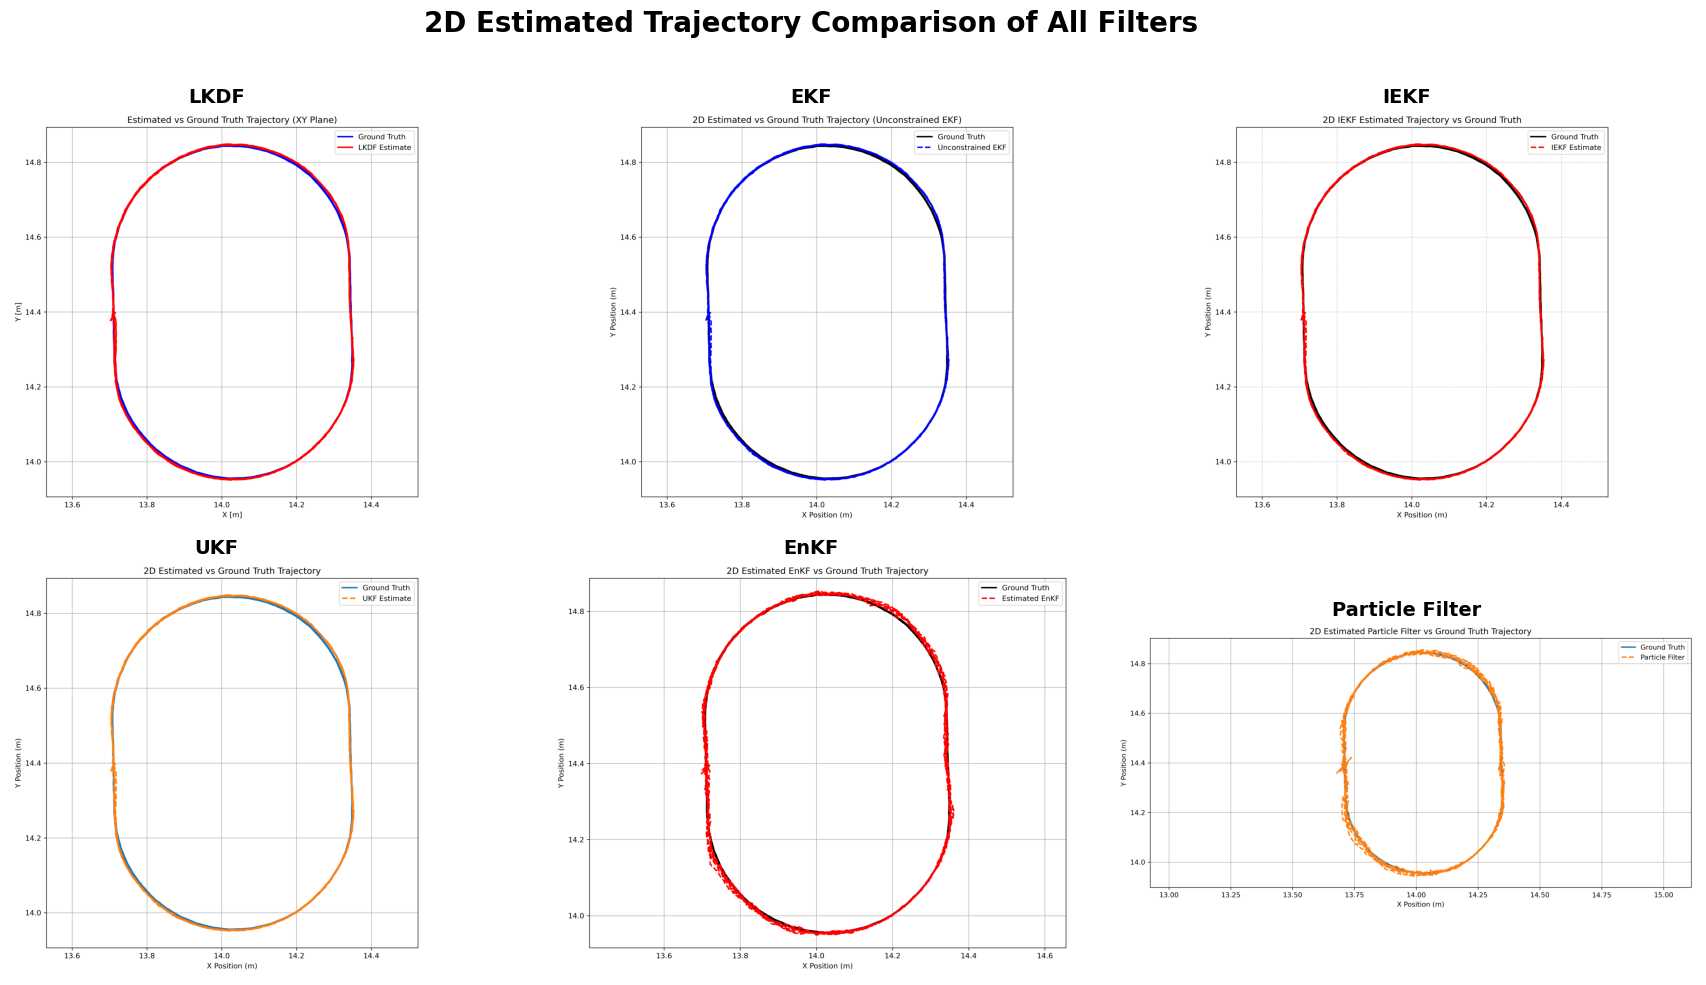

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

folder = "Figures"     # Use for reference to Viewer

images = [
    ("LKDF", "LKDF_2D_Trajectory.png"),
    ("EKF", "EKF_2D_Trajectory.png"),
    ("IEKF", "IEKF_2D_Trajectory.png"),
    ("UKF", "UKF_2D_Trajectory.png"),
    ("EnKF", "EnKF_2D_Trajectory.png"),
    ("Particle Filter", "PF_2D_Trajectory.png"),]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (title, filename) in zip(axes.ravel(), images):

    img_path = os.path.join(folder, filename)

    if os.path.exists(img_path):
        img = mpimg.imread(img_path)
        ax.imshow(img)
        ax.set_title(title, fontsize=14, fontweight='bold')
    else:
        ax.text(0.5, 0.5, "Image Not Found",
                ha='center', va='center', fontsize=12)
        ax.set_title(title, fontsize=14, fontweight='bold')

    ax.axis("off")

plt.suptitle("2D Estimated Trajectory Comparison of All Filters",
             fontsize=20, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- All the filters successfully follow the closed-loop motion of the target, indicating that the chosen dynamic model is suitable for the tracking problem.

- The EKF, IEKF and UKF provide trajectories that almost completely overlap with the ground truth and therefore demonstrate the highest trajectory estimation accuracy. The EnKF achieves good tracking performance with minor stochastic deviations, whereas the Particle Filter exhibits comparatively larger trajectory fluctuations.

# 2.Component-wise Absolute Position Deviation Comparison

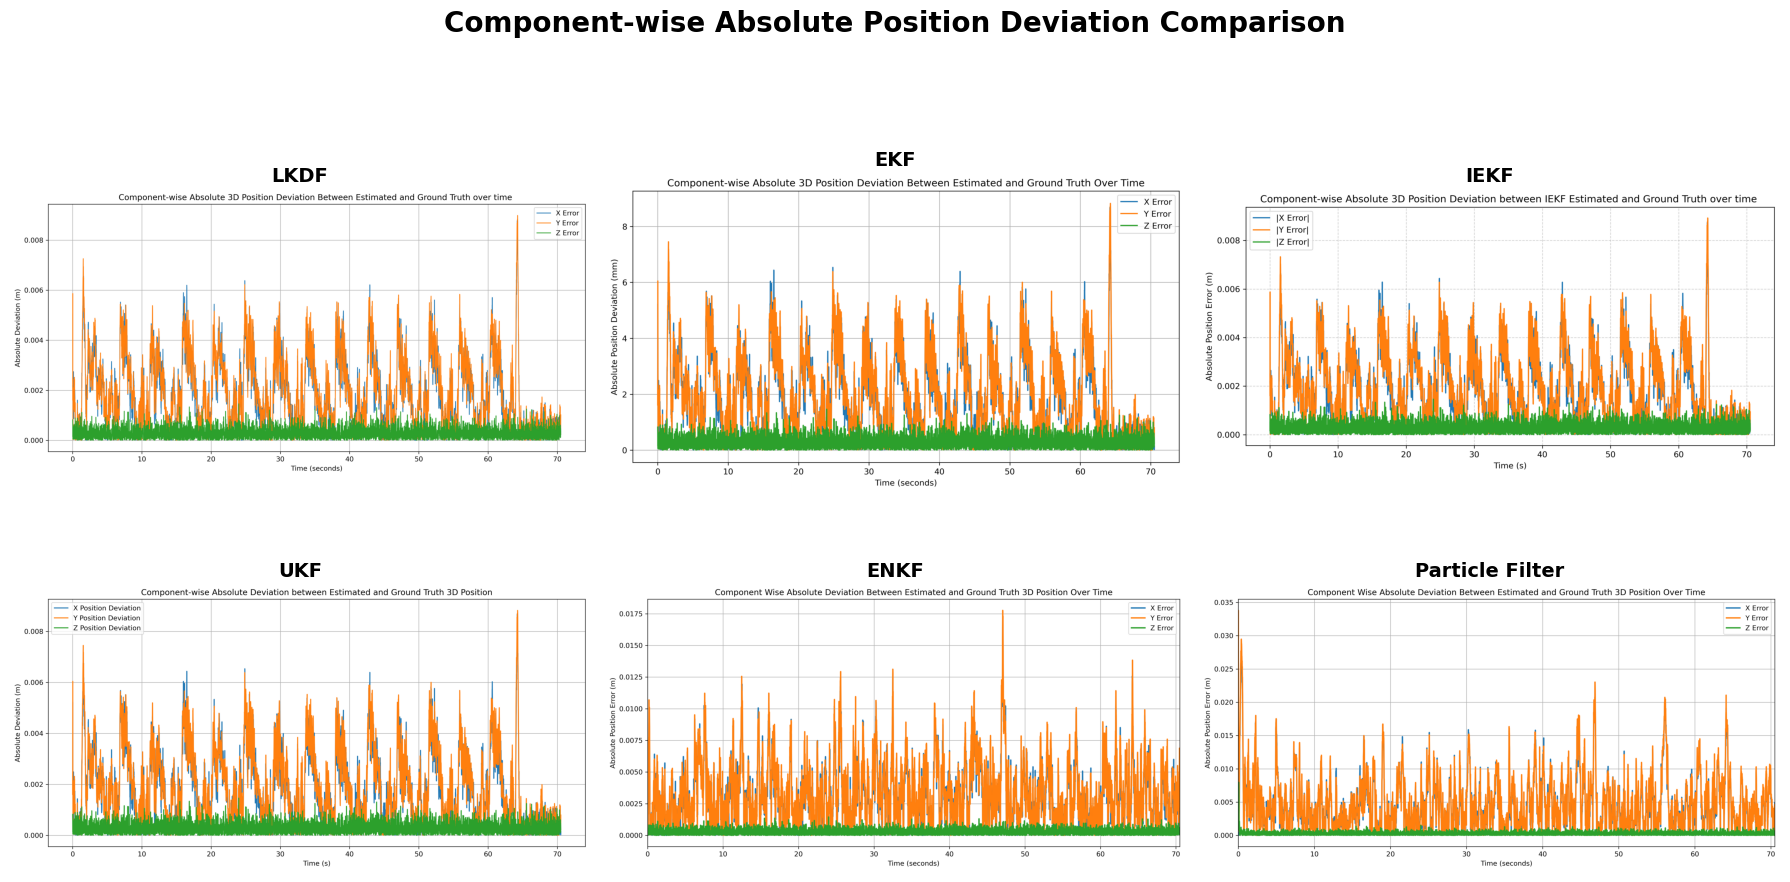

In [2]:
images = [
    ("LKDF", "LKDF_Position_Absolute_deviation.png"),
    ("EKF", "EKF_Position_Absolute_Deviation.png"),
    ("IEKF", "IEKF_Position_Absolute_Deviation.png"),
    ("UKF", "UKF_Position_Absolute_Deviation.png"),
    ("ENKF", "ENKF_Position_Absolute_Deviation.png"),
    ("Particle Filter", "PF_Position_Absolute_Deviation.png"),]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (title, filename) in zip(axes.ravel(), images):

    filepath = os.path.join(folder, filename)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(0.5, 0.5, "Image Not Found",
                ha="center",
                va="center",
                fontsize=12)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "Component-wise Absolute Position Deviation Comparison",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- All the filters successfully tracked the closed-loop robot trajectory, indicating that the selected constant-velocity dynamic model is suitable for the robot tracking problem.

- The LKF, EKF, IEKF, and UKF produced estimated trajectories that almost completely overlapped with the ground truth, demonstrating excellent trajectory estimation accuracy. Among these filters, the **IEKF** and **UKF** exhibited the closest agreement with the reference trajectory.

- The **EnKF** also achieved accurate trajectory tracking, although small stochastic deviations were observed due to the ensemble-based state estimation process.

- The **Particle Filter** successfully followed the overall robot trajectory without divergence; however, it exhibited noticeably larger trajectory fluctuations than the Kalman filter-based approaches because of stochastic particle propagation and the resampling process.

- Overall, the deterministic Kalman filter variants produced smoother and more accurate trajectory estimates than the stochastic filtering approaches, while the Particle Filter exhibited the largest trajectory deviations among the filters investigated.

# 3. Component-wise Absolute Velocity Deviation Comparison


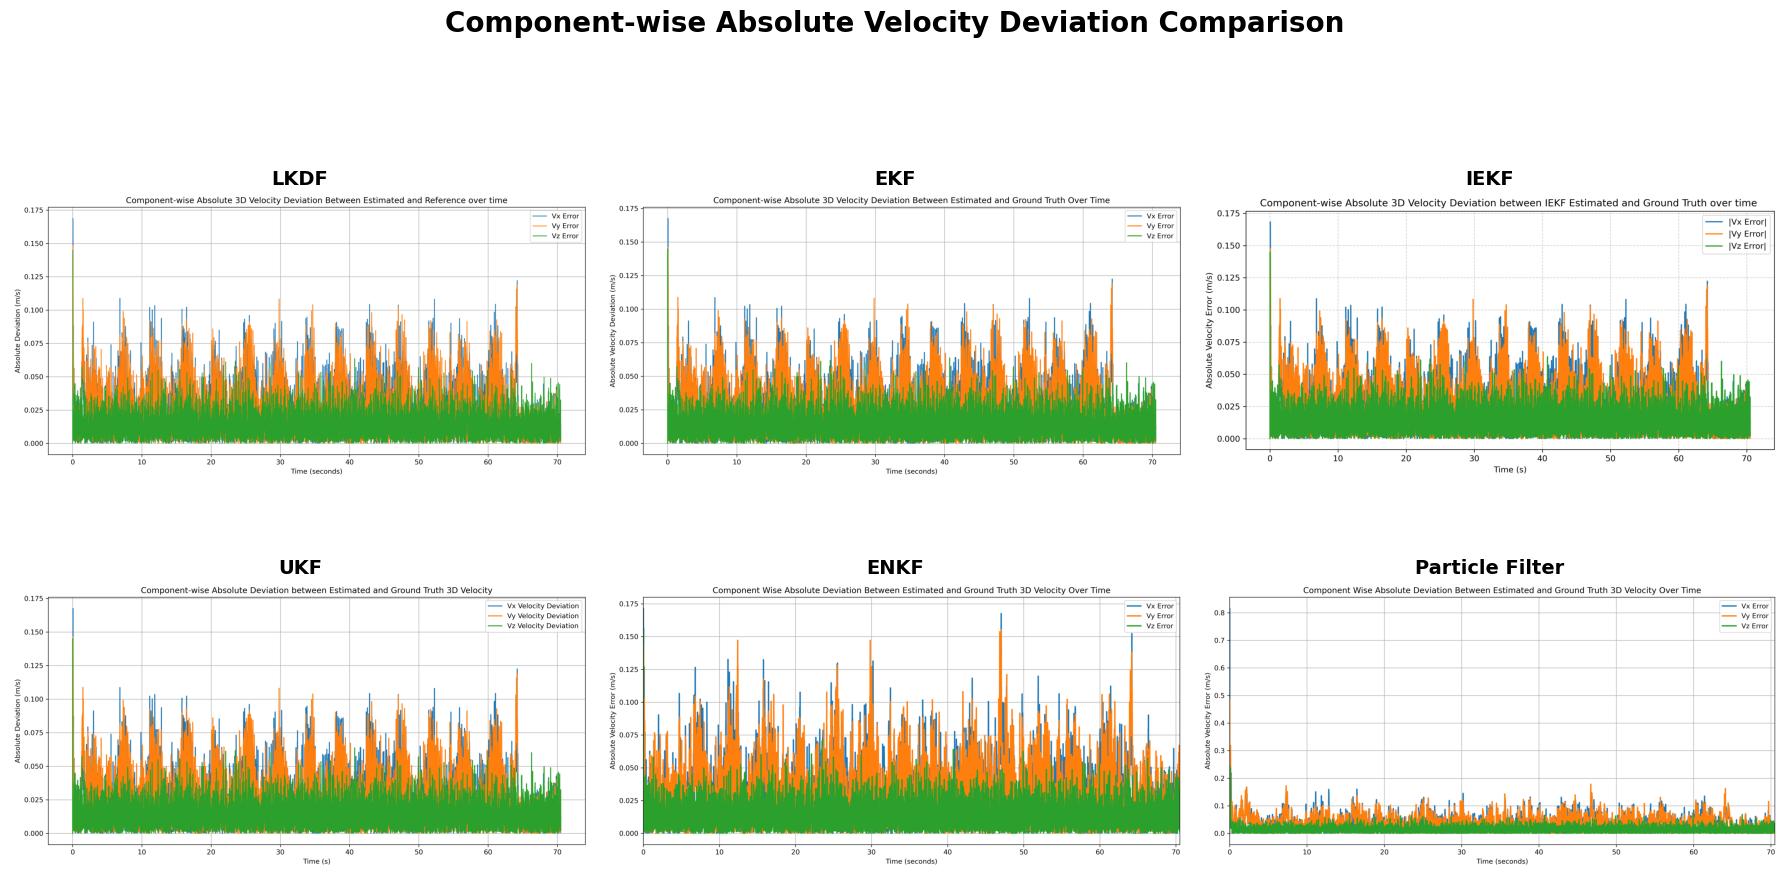

In [3]:
images = [
    ("LKDF", "LKDF_Velocity_Absolute_deviation.png"),
    ("EKF", "EKF_Velocity_Absolute_Deviation.png"),
    ("IEKF", "IEKF_Velocity_Absolute_Deviation.png"),
    ("UKF", "UKF_Velocity_Absolute_Deviation.png"),
    ("ENKF", "ENKF_Velocity_Absolute_Deviation.png"),
    ("Particle Filter", "PF_Velocity_Absolute_Deviation.png"),]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (title, filename) in zip(axes.ravel(), images):

    filepath = os.path.join(folder, filename)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(0.5, 0.5, "Image Not Found",
                ha="center",
                va="center",
                fontsize=12)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "Component-wise Absolute Velocity Deviation Comparison",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- All the filters maintain bounded absolute velocity deviations throughout the robot trajectory, demonstrating stable recursive velocity estimation without divergence.

- The LKF, EKF, IEKF, and UKF exhibit the smallest and most consistent absolute velocity deviations. Among these filters, the **IEKF** and **UKF** produce the lowest deviations, indicating the highest velocity estimation accuracy.

- The **EnKF** also provides stable velocity estimates with only minor stochastic fluctuations arising from the ensemble-based estimation process.

- The **Particle Filter** maintains bounded velocity deviations throughout the experiment; however, it exhibits comparatively larger fluctuations due to stochastic particle propagation and repeated resampling operations.

- Overall, the **IEKF** and **UKF** provide the most accurate and consistent velocity estimates, followed closely by the **LKF** and **EKF**. Although the **EnKF** achieves reliable estimation performance, the **Particle Filter** exhibits the largest absolute velocity deviations among the filters investigated.

# 4. Component-wise Cumulative 3D Position RMSE Comparison

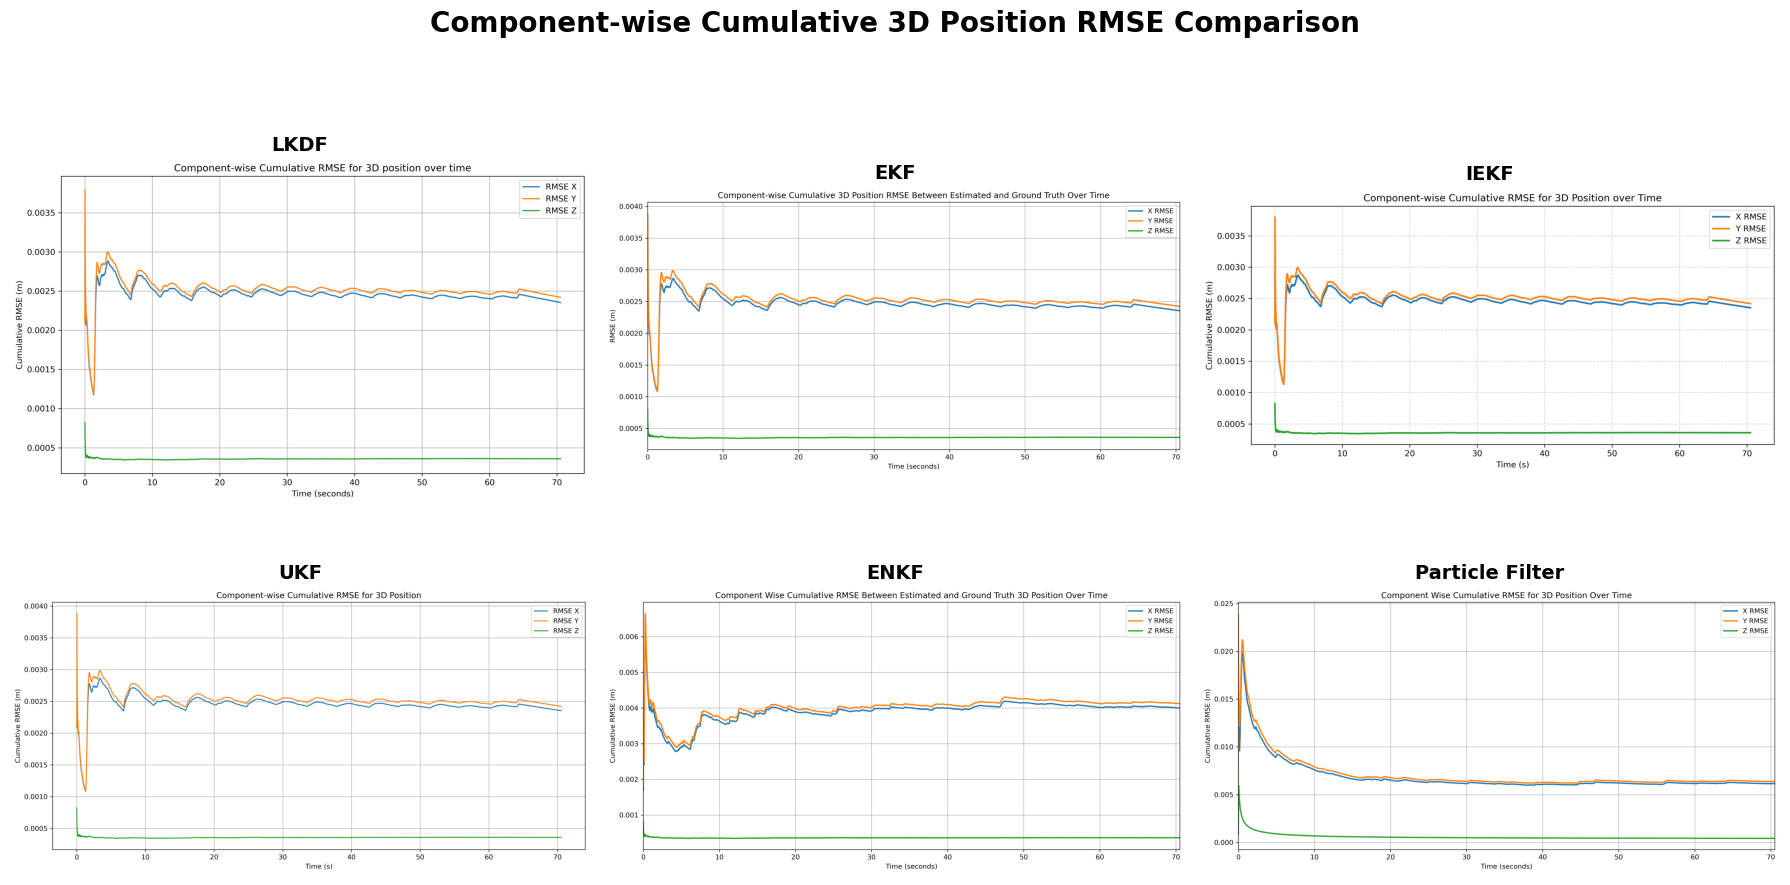

In [4]:
images = [
    ("LKDF", "LKDF_Component_Cumulative_PositionRMSE.png"),
    ("EKF", "EKF_Component_Cumulative_PositionRMSE.png"),
    ("IEKF", "IEKF_Component_Cumulative_PositionRMSE.png"),
    ("UKF", "UKF_Component_Cumulative_PositionRMSE.png"),
    ("ENKF", "ENKF_Component_Cumulative_PositionRMSE.png"),
    ("Particle Filter", "PF_Component_Cumulative_PositionRMSE.png"),]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (title, filename) in zip(axes.ravel(), images):

    filepath = os.path.join(folder, filename)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5, 0.5,
            "Image Not Found",
            ha="center",
            va="center",
            fontsize=12)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "Component-wise Cumulative 3D Position RMSE Comparison",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0,0,1,0.96])

plt.show()

### Summary:

- The component-wise cumulative position RMSE plots show that all six filters converge rapidly during the initial stage of estimation before reaching a stable steady-state error, demonstrating consistent recursive position estimation throughout the robot tracking experiment.

- The Linear Kalman Filter, Extended Kalman Filter, Iterated Extended Kalman Filter, and Unscented Kalman Filter achieve the lowest and most stable cumulative position RMSE values. Among these filters, the Iterated Extended Kalman Filter produces the smallest overall position RMSE, followed very closely by the Linear Kalman Filter and the Unscented Kalman Filter.

- The Ensemble Kalman Filter also converges successfully and provides reliable position estimates, although small stochastic fluctuations are observed because of the ensemble-based estimation process.

- The Particle Filter converges without divergence but exhibits comparatively larger cumulative position RMSE than the Kalman filter-based approaches because of stochastic particle propagation and repeated resampling operations.

- Overall, the Iterated Extended Kalman Filter provides the best cumulative position estimation performance, followed closely by the Linear Kalman Filter, Unscented Kalman Filter, and Extended Kalman Filter. The Ensemble Kalman Filter achieves good estimation accuracy with minor stochastic variations, whereas the Particle Filter exhibits the largest cumulative position RMSE among the filters investigated.

# 5. Overall Cumulative 3D Position RMSE Comparison

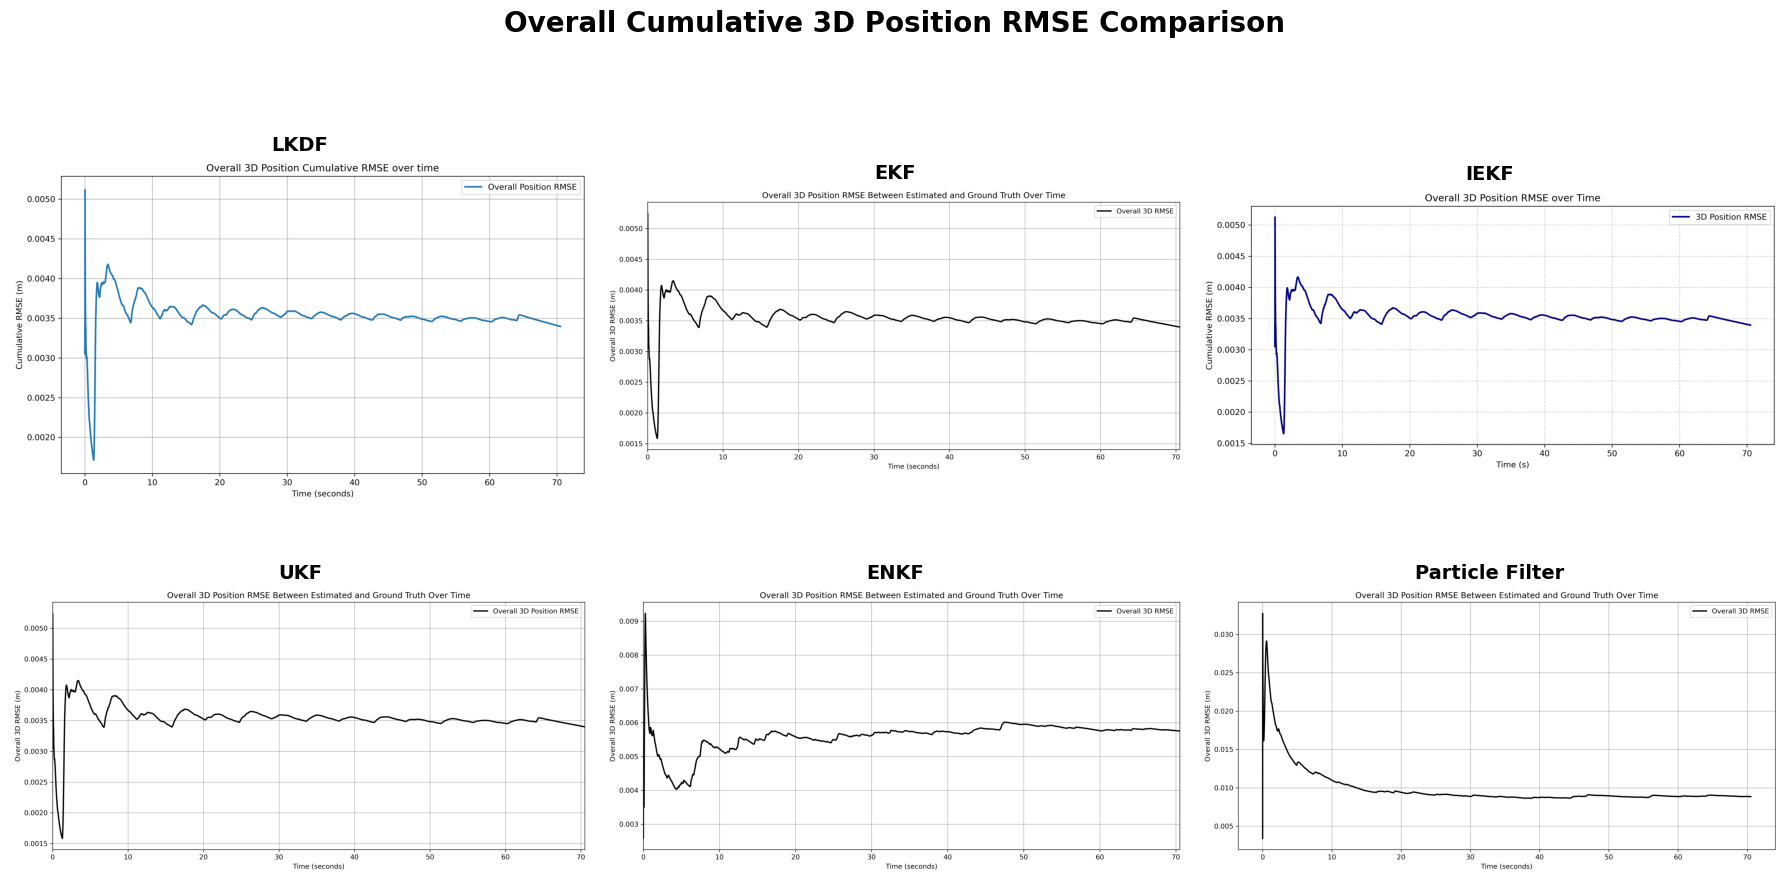

In [5]:
images = [
    ("LKDF", "LKDF_Overall_Cumulative_PositionRMSE.png"),
    ("EKF", "EKF_Overall_Cumulative_PositionRMSE.png"),
    ("IEKF", "IEKF_Overall_Cumulative_PositionRMSE.png"),
    ("UKF", "UKF_Overall_Cumulative_PositionRMSE.png"),
    ("ENKF", "ENKF_Overall_Cumulative_PositionRMSE.png"),
    ("Particle Filter", "PF_Overall_Cumulative_PositionRMSE.png"),]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (title, filename) in zip(axes.ravel(), images):

    filepath = os.path.join(folder, filename)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            "Image Not Found",
            ha="center",
            va="center",
            fontsize=12,)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "Overall Cumulative 3D Position RMSE Comparison",
    fontsize=20,
    fontweight="bold",)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- The overall cumulative three-dimensional position RMSE plots show that all six filters converge rapidly during the initial stage of estimation before reaching stable steady-state values, demonstrating good convergence throughout the robot tracking experiment.

- The Iterated Extended Kalman Filter achieves the lowest overall cumulative position RMSE, followed very closely by the Linear Kalman Filter and the Unscented Kalman Filter. The Extended Kalman Filter also provides highly accurate position estimates with only a marginal increase in cumulative RMSE.

- The Ensemble Kalman Filter converges successfully and produces reliable position estimates, although small stochastic fluctuations are observed because of the ensemble-based estimation process.

- The Particle Filter exhibits the largest overall cumulative position RMSE among the filters investigated. The stochastic particle propagation and repeated resampling process introduce greater estimation variability than the Kalman filter-based approaches.

- Overall, the Iterated Extended Kalman Filter provides the highest overall position estimation accuracy, followed closely by the Linear Kalman Filter, Unscented Kalman Filter, and Extended Kalman Filter. The Ensemble Kalman Filter achieves satisfactory estimation performance despite minor stochastic variations, whereas the Particle Filter produces the largest cumulative position RMSE for the robot tracking problem considered in this study.

# 6. Component-wise Cumulative 3D Velocity RMSE Comparison

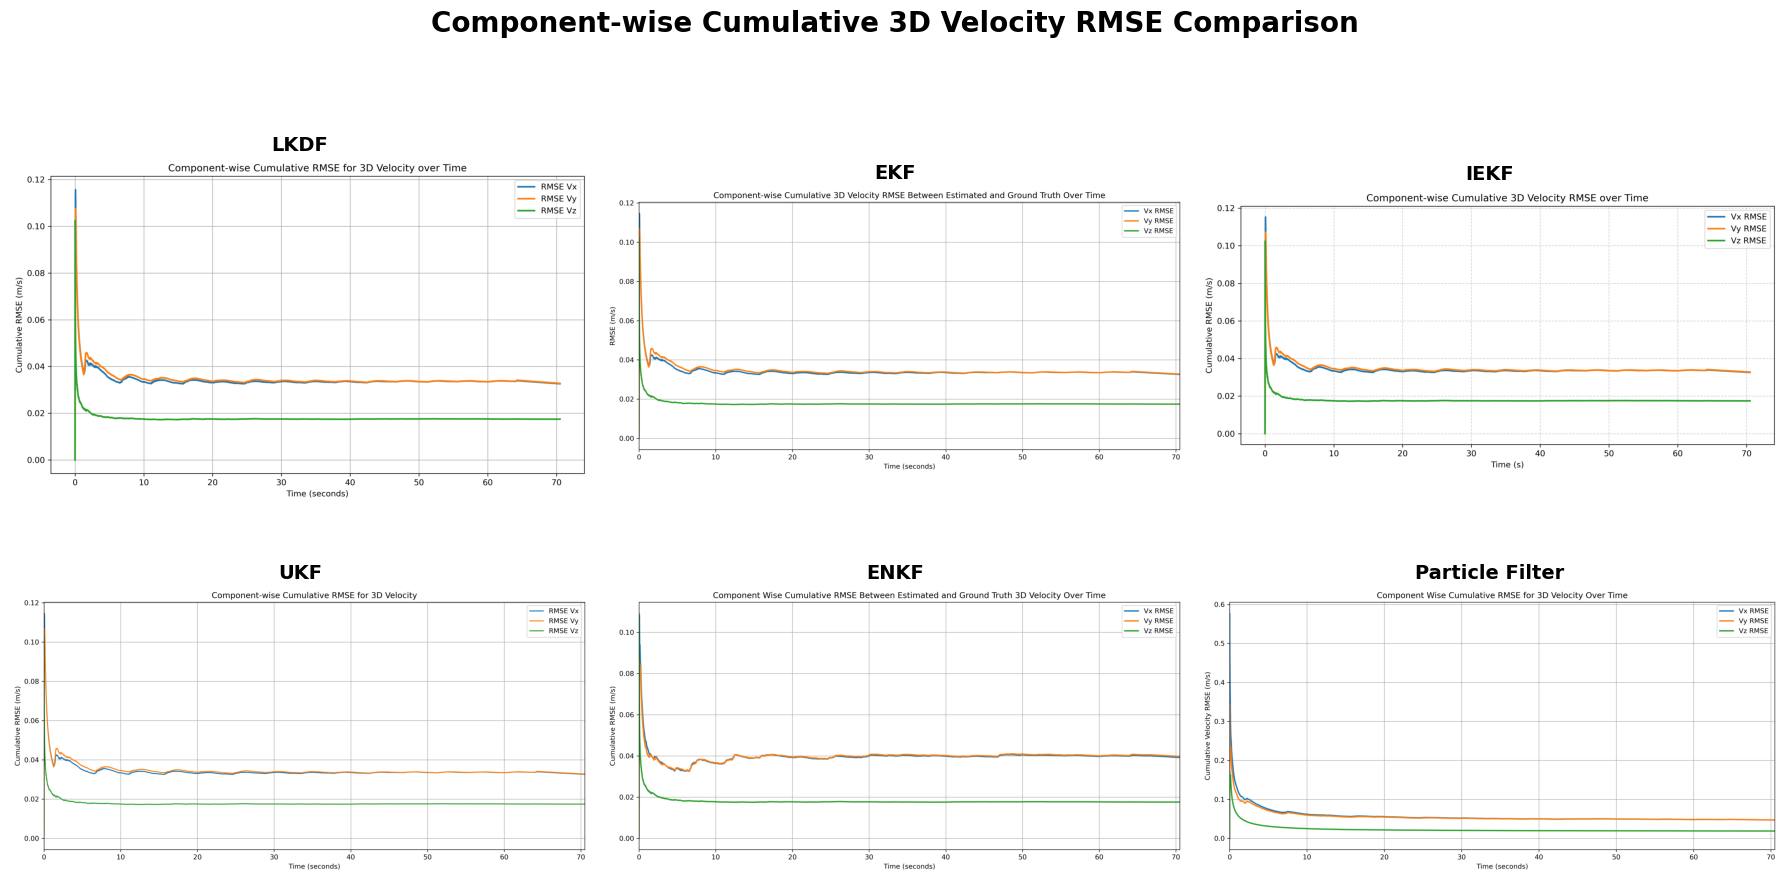

In [6]:
images = [
    ("LKDF", "LKDF_Component_Cumulative_VelocityRMSE.png"),
    ("EKF", "EKF_Component_Cumulative_VelocityRMSE.png"),
    ("IEKF", "IEKF_Component_Cumulative_VelocityRMSE.png"),
    ("UKF", "UKF_Component_Cumulative_VelocityRMSE.png"),
    ("ENKF", "ENKF_Component_Cumulative_VelocityRMSE.png"),
    ("Particle Filter", "PF_Component_Cumulative_VelocityRMSE.png"),]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (title, filename) in zip(axes.ravel(), images):

    filepath = os.path.join(folder, filename)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            "Image Not Found",
            ha="center",
            va="center",
            fontsize=12,)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "Component-wise Cumulative 3D Velocity RMSE Comparison",
    fontsize=20,
    fontweight="bold",)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- The component-wise cumulative three-dimensional velocity RMSE plots show that all six filters converge rapidly during the initial stage of estimation before reaching stable steady-state values, demonstrating consistent and stable velocity estimation throughout the robot tracking experiment.

- The Linear Kalman Filter, Extended Kalman Filter, Iterated Extended Kalman Filter, and Unscented Kalman Filter exhibit very similar convergence characteristics, with the velocity RMSE stabilising rapidly after a short transient period.

- Among the deterministic Kalman filter variants, the Iterated Extended Kalman Filter achieves the lowest cumulative velocity RMSE, followed very closely by the Linear Kalman Filter and the Unscented Kalman Filter. The Extended Kalman Filter also provides accurate velocity estimation with only a marginal increase in cumulative RMSE.

- The Ensemble Kalman Filter converges smoothly and maintains stable velocity estimates throughout the experiment, although small stochastic fluctuations are observed because of the ensemble-based estimation process. The Particle Filter follows a different convergence pattern, with a larger initial velocity RMSE that gradually decreases before reaching a steady-state value.

- Overall, the Iterated Extended Kalman Filter provides the highest velocity estimation accuracy, followed closely by the Linear Kalman Filter, Unscented Kalman Filter, and Extended Kalman Filter. The Ensemble Kalman Filter achieves satisfactory estimation performance despite minor stochastic variations, whereas the Particle Filter exhibits the largest cumulative velocity RMSE among the filters investigated.

# 7. Overall Cumulative 3D Velocity RMSE Comparison

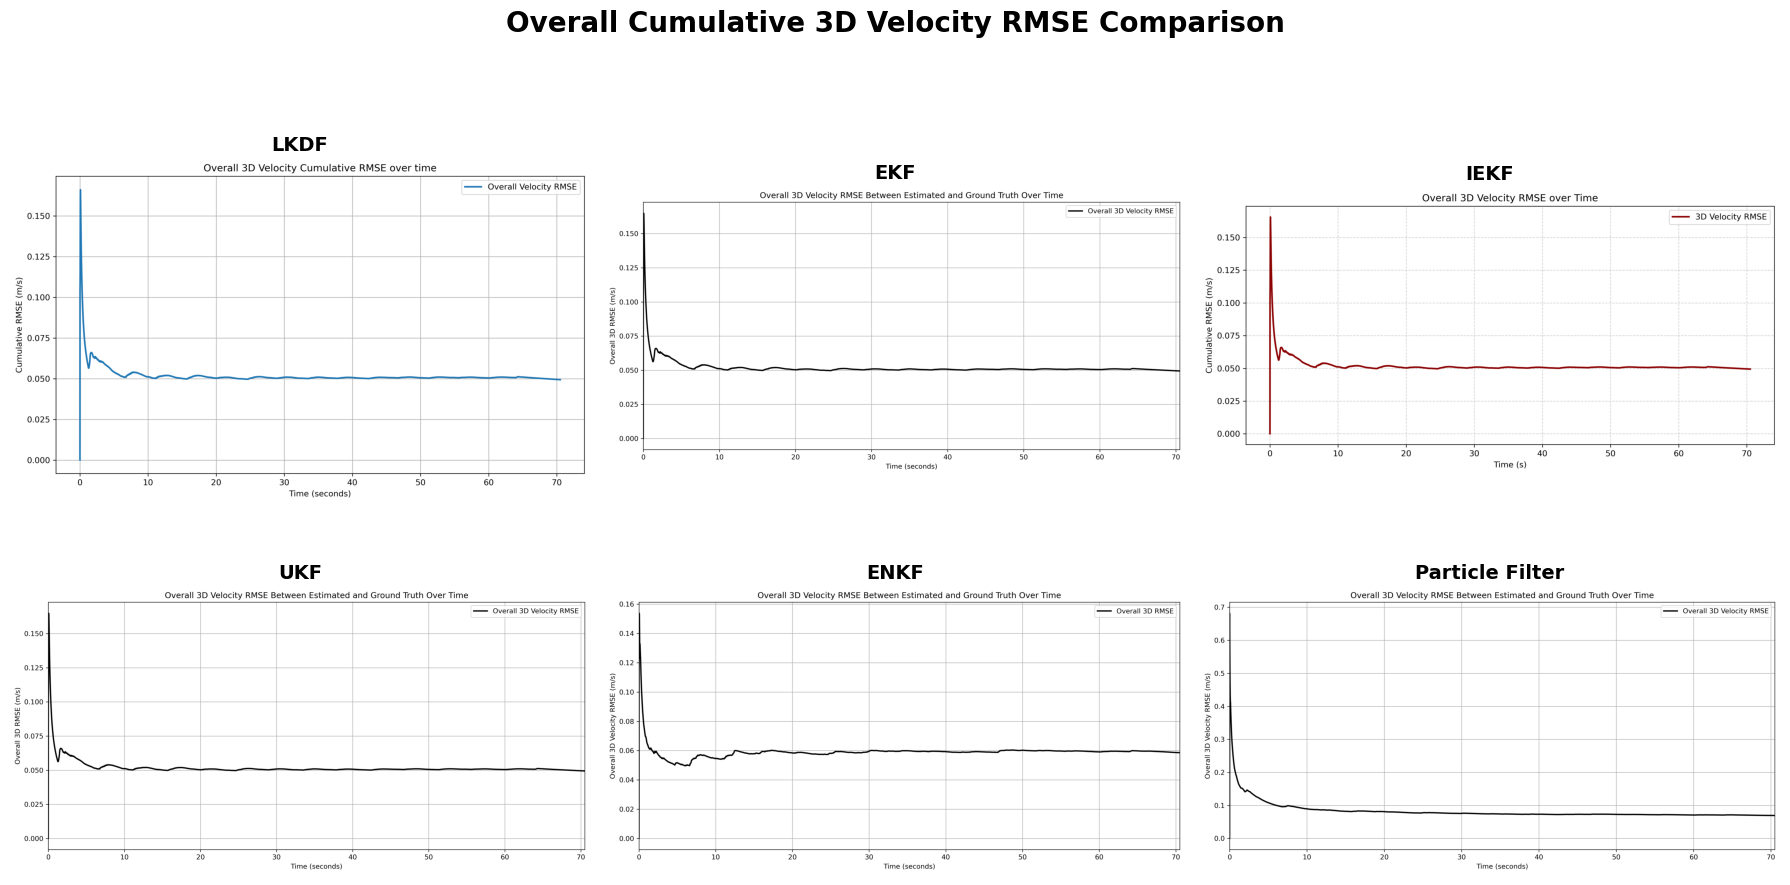

In [7]:
images = [
    ("LKDF", "LKDF_Overall_Cumulative_VelocityRMSE.png"),
    ("EKF", "EKF_Overall_Cumulative_VelocityRMSE.png"),
    ("IEKF", "IEKF_Overall_Cumulative_VelocityRMSE.png"),
    ("UKF", "UKF_Overall_Cumulative_VelocityRMSE.png"),
    ("ENKF", "ENKF_Overall_Cumulative_VelocityRMSE.png"),
    ("Particle Filter", "PF_Overall_Cumulative_VelocityRMSE.png"),]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (title, filename) in zip(axes.ravel(), images):

    filepath = os.path.join(folder, filename)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            "Image Not Found",
            ha="center",
            va="center",
            fontsize=12,)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "Overall Cumulative 3D Velocity RMSE Comparison",
    fontsize=20,
    fontweight="bold",)

plt.tight_layout(rect=[0,0,1,0.96])

plt.show()

### Summary:

- The overall cumulative three-dimensional velocity RMSE plots show that all six filters converge rapidly during the initial stage of estimation before reaching stable steady-state values, demonstrating reliable and consistent velocity estimation throughout the robot tracking experiment.

- The Iterated Extended Kalman Filter achieves the lowest overall cumulative velocity RMSE, followed very closely by the Linear Kalman Filter and the Unscented Kalman Filter. The Extended Kalman Filter also provides highly accurate velocity estimation with only a marginal increase in steady-state RMSE.

- The Ensemble Kalman Filter converges smoothly and maintains stable velocity estimation throughout the experiment, although minor stochastic fluctuations are present because of the ensemble-based estimation process.

- The Particle Filter also converges successfully but maintains the largest overall cumulative velocity RMSE among the filters investigated. The stochastic particle propagation and repeated resampling process introduce greater estimation variability than the Kalman filter-based approaches.

- Overall, the Iterated Extended Kalman Filter provides the highest velocity estimation accuracy, followed closely by the Linear Kalman Filter, Unscented Kalman Filter, and Extended Kalman Filter. The Ensemble Kalman Filter achieves satisfactory performance despite minor stochastic variations, whereas the Particle Filter exhibits the largest cumulative velocity RMSE for the robot tracking problem considered in this study.

# 8. Numerical RMSE Comparison

| Filter | Best Configuration | Position RMSE (m) | Velocity RMSE (m/s) | Remarks |
|:------|:----------------------|------------------:|--------------------:|:--------------------------------------------------------------|
| Linear Kalman Filter | $\sigma_a = 2.5$ | **0.003397641** | **0.049443000** | Excellent estimation accuracy for the approximately linear robot tracking problem. |
| Extended Kalman Filter | Unconstrained ($\sigma_a = 2.5$) | **0.003411219** | **0.050639352** | Accurate nonlinear estimation with only a slight increase in RMSE compared with the Linear Kalman Filter. |
| Iterated Extended Kalman Filter | Unconstrained ($\sigma_a = 2.5$) | **0.003394869** | **0.049441306** | Best overall estimation accuracy among the recursive Gaussian filters due to iterative measurement refinement. |
| Unscented Kalman Filter | $\sigma_a = 2.5$ | **0.003397641** | **0.049443000** | Estimation accuracy comparable to the Linear Kalman Filter while avoiding Jacobian computation. |
| Ensemble Kalman Filter | $\sigma_a = 2.5,\;N_e = 500$ | **0.005757305** | **0.058650516** | Stable estimation with minor stochastic sampling errors, although less accurate than the deterministic Kalman filters. |
| Particle Filter | $\sigma_a = 2.5,\;N_p = 1500$ | **0.008856500** | **0.069301336** | Highest estimation error among the filters considered, primarily due to stochastic particle sampling and resampling effects. |

# 9. Improvement over Raw Sensor Measurements

| Filter | Best Configuration | Position Improvement (%) | Velocity Improvement (%) | Observation |
|:------|:---------------------------|-------------------------:|-------------------------:|:--------------------------------------------------------------|
| Linear Kalman Filter | $\sigma_a = 2.5$ | **-26.76** | **73.89** | Excellent improvement in velocity estimation, although the highly accurate sensor position measurements remain superior. |
| Extended Kalman Filter | Unconstrained ($\sigma_a = 2.5$) | **-27.27** | **73.26** | Similar performance to the Linear Kalman Filter, with significant velocity improvement but slightly larger position errors. |
| Iterated Extended Kalman Filter | Unconstrained ($\sigma_a = 2.5$) | **-26.66** | **73.89** | Highest overall improvement among the Gaussian recursive filters due to iterative measurement refinement. |
| Unscented Kalman Filter | $\sigma_a = 2.5$ | **-26.76** | **73.89** | Performance comparable to the Linear Kalman Filter while avoiding Jacobian linearization. |
| Ensemble Kalman Filter | $\sigma_a = 2.5,\;N_e = 500$ | **-114.79** | **69.03** | Improved velocity estimation but produced larger position errors than the direct sensor measurements because of stochastic sampling. |
| Particle Filter | $\sigma_a = 2.5,\;N_p = 1500$ | **-230.41** | **63.40** | Improved velocity estimation but yielded the largest position errors among the filters because of stochastic particle sampling and resampling effects. |

## 10. Computation Time Comparison

| Filter | Best Configuration | Total Time (s) | Average Time / Epoch (ms) | Relative Speed | Observation |
|:------|:----------------------|---------------:|--------------------------:|:---------------|:--------------------------------------------------------------|
| Extended Kalman Filter | Unconstrained ($\sigma_a=2.5$) | **1.276510** | **0.1809** | Fastest | Lowest execution time among all nonlinear filters because only a single prediction and update are performed at each epoch. |
| Linear Kalman Filter | $\sigma_a=2.5$ | **1.551514** | **0.2199** | Very Fast | Linear state-space formulation results in low computational cost and efficient recursive estimation. |
| Iterated Extended Kalman Filter | Unconstrained ($\sigma_a=2.5$) | **1.555349** | **0.2204** | Very Fast | Slight increase in computation time due to repeated measurement refinement during each update. |
| Unscented Kalman Filter | $\sigma_a=2.5$ | **4.252421** | **0.6027** | Moderate | Sigma-point generation and nonlinear propagation increase the computational cost while maintaining high estimation accuracy. |
| Ensemble Kalman Filter | $\sigma_a=2.5,\;N_e=500$ | **1045.094836** | **148.1143** | Slow | Propagation of a large ensemble and covariance computation significantly increase the execution time. |
| Particle Filter | $\sigma_a=2.5,\;N_p=1500$ | **1270.928221** | **180.1202** | Slowest | Particle propagation, likelihood evaluation, weight normalisation, and repeated resampling make it the most computationally expensive filter. |

## Convergence Behaviour Comparison Summary

- All six filters successfully converged and accurately tracked the robot throughout the trajectory, demonstrating that the selected dynamic model and measurement model are appropriate for the robot tracking problem.

- The Linear Kalman Filter exhibited stable convergence despite assuming a linear system model, indicating that the selected motion model adequately represents the robot dynamics for the present study.

- The Extended Kalman Filter converged rapidly by incorporating the nonlinear measurement model and maintained stable estimation throughout the tracking process.

- The Iterated Extended Kalman Filter achieved the best overall convergence behaviour. The iterative measurement refinement reduced the linearisation error at each measurement epoch, allowing the filter to converge to the most accurate steady-state solution while maintaining numerical stability.

- The Unscented Kalman Filter also demonstrated smooth and stable convergence. The deterministic sigma-point approach effectively captured the system nonlinearity without requiring Jacobian matrices, resulting in convergence behaviour comparable to that of the Iterated Extended Kalman Filter.

- The Ensemble Kalman Filter converged successfully and maintained stable tracking throughout the experiment. Minor stochastic fluctuations were observed because the state covariance was estimated from a finite ensemble of randomly propagated samples.

- The Particle Filter also converged successfully without divergence. However, stochastic particle propagation and repeated resampling introduced greater estimation variability than the Kalman filter-based approaches, resulting in larger steady-state estimation errors despite maintaining reliable robot tracking throughout the experiment.

## Final Assessment of the Unconstrained Filters

#### Linear Kalman Filter
Provided excellent estimation accuracy with stable convergence despite the linear system assumption, demonstrating that the selected motion model adequately represents the robot dynamics.

#### Extended Kalman Filter
Improved the state estimation by incorporating the nonlinear measurement model, producing accurate and stable recursive estimates with only a marginal increase in RMSE compared with the best-performing filters.

#### Iterated Extended Kalman Filter
Achieved the best overall estimation performance owing to iterative measurement refinement, resulting in the lowest overall position and velocity RMSE while maintaining excellent convergence and numerical stability.

#### Unscented Kalman Filter
Produced estimation accuracy comparable to the Linear Kalman Filter while effectively handling system nonlinearity without requiring Jacobian matrices, resulting in excellent convergence and numerical robustness.

#### Ensemble Kalman Filter
Provided reliable estimation with stable convergence and satisfactory accuracy, although stochastic ensemble sampling resulted in higher RMSE than the Linear Kalman Filter, Extended Kalman Filter, Iterated Extended Kalman Filter, and Unscented Kalman Filter.

#### Particle Filter
Successfully tracked the robot throughout the experiment with stable convergence; however, stochastic particle propagation and repeated resampling resulted in the highest position and velocity RMSE among the filters investigated.

### Iterated Extended Kalman Filter(Best filter among the unconstrained variants):
Achieves the best overall performance among all six filters due to iterative refinement resulting in the lowest position and velocity RMSE.

# Explicit Comparison of Constrained Filters 
## 1. 2D Estimated Trajectory Comparison of EKF and IEKF Variants

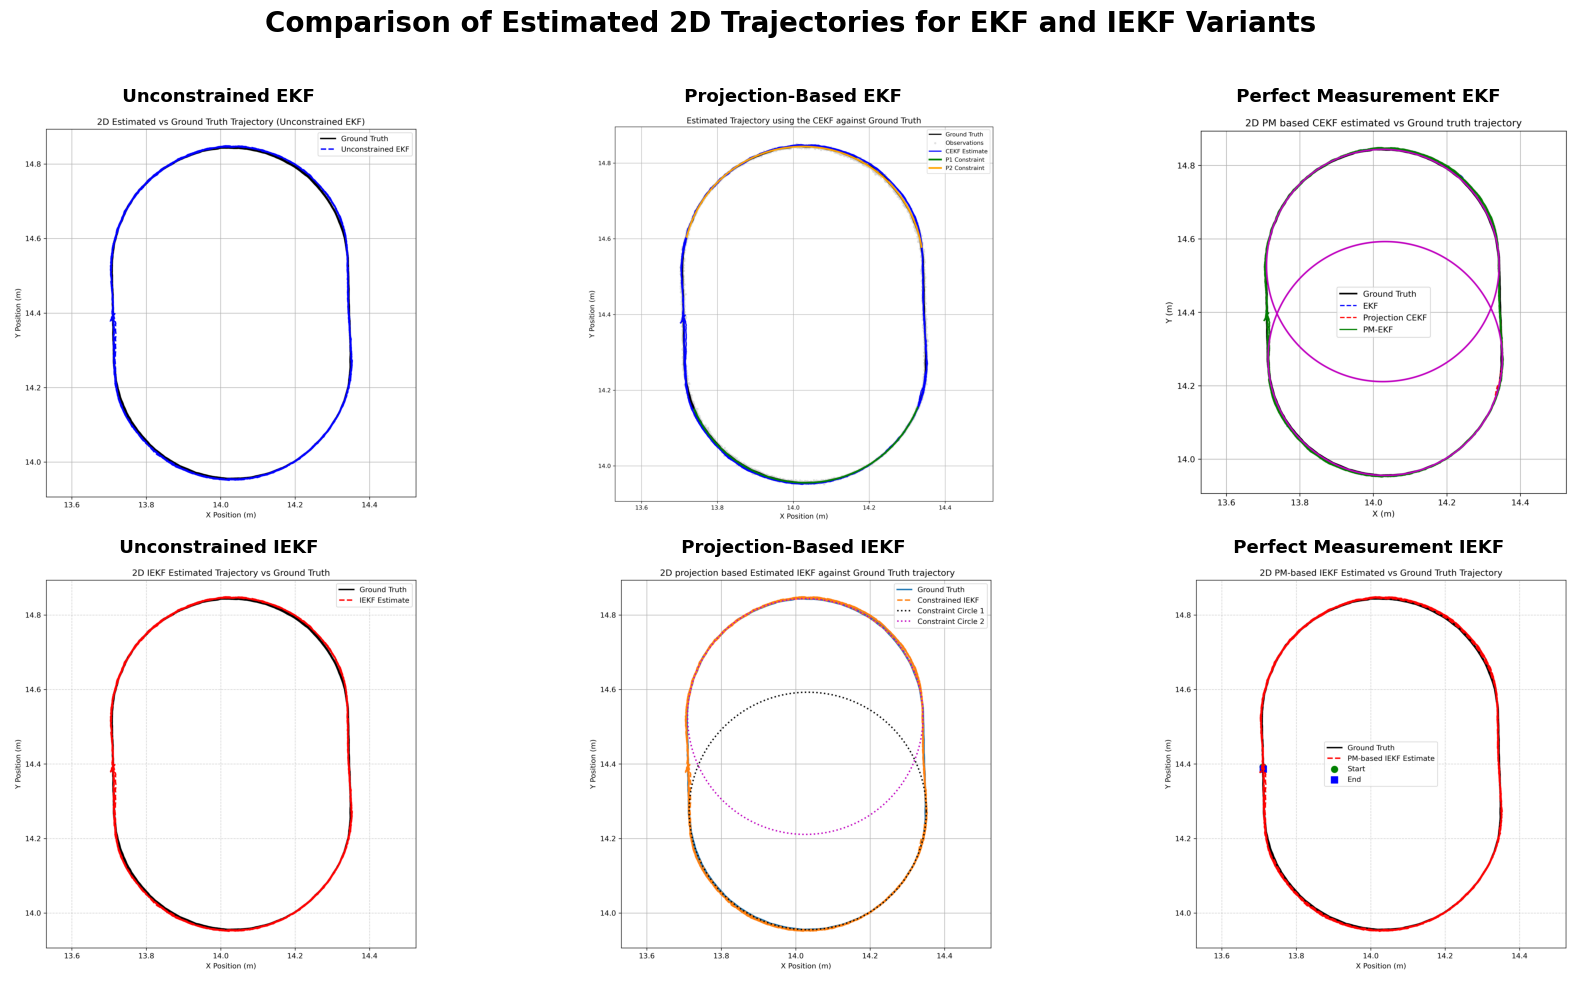

In [8]:
titles = [
    " Unconstrained EKF",
    " Projection-Based EKF",
    " Perfect Measurement EKF",
    " Unconstrained IEKF",
    " Projection-Based IEKF",
    " Perfect Measurement IEKF"]

images = [
    "EKF_2D_Trajectory.png",
    "Projection_EKF_2D_Trajectory.png",
    "PM_EKF_2D_Trajectory.png",
    "IEKF_2D_Trajectory.png",
    "_Projection_IEKF_2D_Trajectory.png",
    "_PM_IEKF_2D_Trajectory.png"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, title, image in zip(axes.ravel(), titles, images):

    filepath = os.path.join(folder, image)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            f"Image Not Found\n{image}",
            ha="center",
            va="center",
            fontsize=11)

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=8)

    ax.axis("off")

plt.suptitle(
    "Comparison of Estimated 2D Trajectories for EKF and IEKF Variants",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- All six methods successfully tracked the robot trajectory and closely followed the ground truth, demonstrating stable recursive estimation throughout the experiment.

- The unconstrained Extended Kalman Filter and Iterated Extended Kalman Filter produced highly accurate trajectory estimates, with the Iterated Extended Kalman Filter exhibiting slightly better agreement with the ground truth because the iterative measurement update reduced the linearisation error.

- The projection-based Extended Kalman Filter and Iterated Extended Kalman Filter successfully enforced the geometric constraint while maintaining accurate trajectory estimation. Although the projection ensured geometric consistency, it introduced a slight increase in estimation error compared with the corresponding unconstrained filters.

- The perfect measurement Extended Kalman Filter and Iterated Extended Kalman Filter incorporated the geometric constraint directly into the measurement update, simultaneously satisfying the measurement information and the motion constraint. Consequently, these methods achieved the closest agreement with the reference trajectory and the lowest estimation errors among the constrained approaches.

- Comparing the Extended Kalman Filter and Iterated Extended Kalman Filter families, the Iterated Extended Kalman Filter variants consistently produced slightly more accurate trajectory estimates than the corresponding Extended Kalman Filter variants. Furthermore, the perfect measurement approach outperformed the projection-based approach by providing improved estimation accuracy while maintaining geometric consistency.

## 2. Comparison of Component-wise Absolute Position Deviations for EKF and IEKF Variants

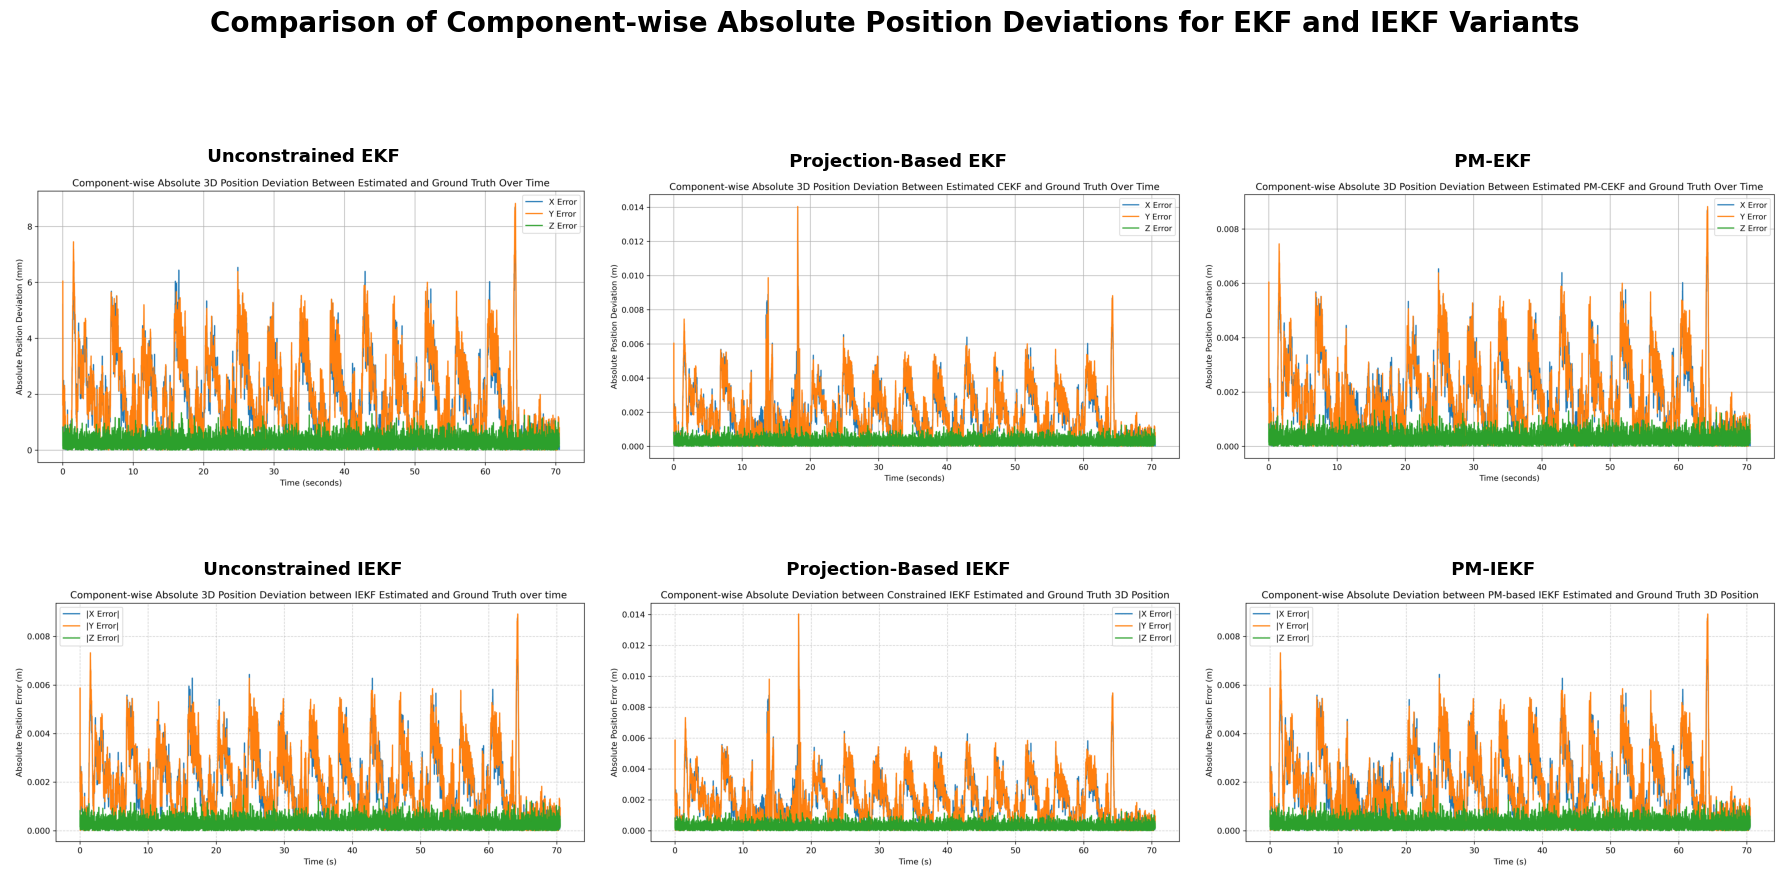

In [9]:
# Subplot titles
titles = [
    " Unconstrained EKF",
    " Projection-Based EKF",
    " PM-EKF",
    " Unconstrained IEKF",
    " Projection-Based IEKF",
    " PM-IEKF"]


# Image names
images = [
    "EKF_Position_Absolute_Deviation.png",
    "Projection_EKF_Position_Absolute_Deviation.png",
    "PM_EKF_Position_Absolute_Deviation.png",
    "IEKF_Position_Absolute_Deviation.png",
    "Projection_IEKF_Position_Absolute_Deviation.png",
    "PM_IEKF_Position_Absolute_Deviation.png"]

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, title, image in zip(axes.ravel(), titles, images):

    filepath = os.path.join(folder, image)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            f"Image Not Found\n{image}",
            ha="center",
            va="center",
            fontsize=11)

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=8)

    ax.axis("off")

plt.suptitle(
    "Comparison of Component-wise Absolute Position Deviations for EKF and IEKF Variants",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- The unconstrained Extended Kalman Filter and Iterated Extended Kalman Filter produce small and stable absolute position deviations throughout the robot tracking experiment. The Iterated Extended Kalman Filter exhibits slightly lower deviations because the iterative measurement update reduces the effect of nonlinear linearisation errors.

- The projection-based Extended Kalman Filter and Iterated Extended Kalman Filter successfully enforce the geometric constraint while maintaining stable position estimation. Although the estimated trajectory satisfies the prescribed constraint, the projection step introduces a slight increase in the position deviations compared with the corresponding unconstrained filters.

- The Perfect Measurement Extended Kalman Filter and Perfect Measurement Iterated Extended Kalman Filter exhibit the smallest absolute position deviations among the constrained approaches by incorporating the geometric constraint directly into the measurement update, thereby improving estimation accuracy while maintaining geometric consistency.

- Comparing the constrained methods, the Perfect Measurement approach consistently outperforms the projection-based approach by producing lower position deviations and smoother estimation throughout the robot trajectory.

- Overall, the Iterated Extended Kalman Filter variants produce slightly more consistent position estimates than the corresponding Extended Kalman Filter variants, and the Perfect Measurement Iterated Extended Kalman Filter provides the best overall position estimation performance among the six methods investigated.

## 3. Comparison of Component-wise Absolute Velocity Deviations for EKF and IEKF Variants

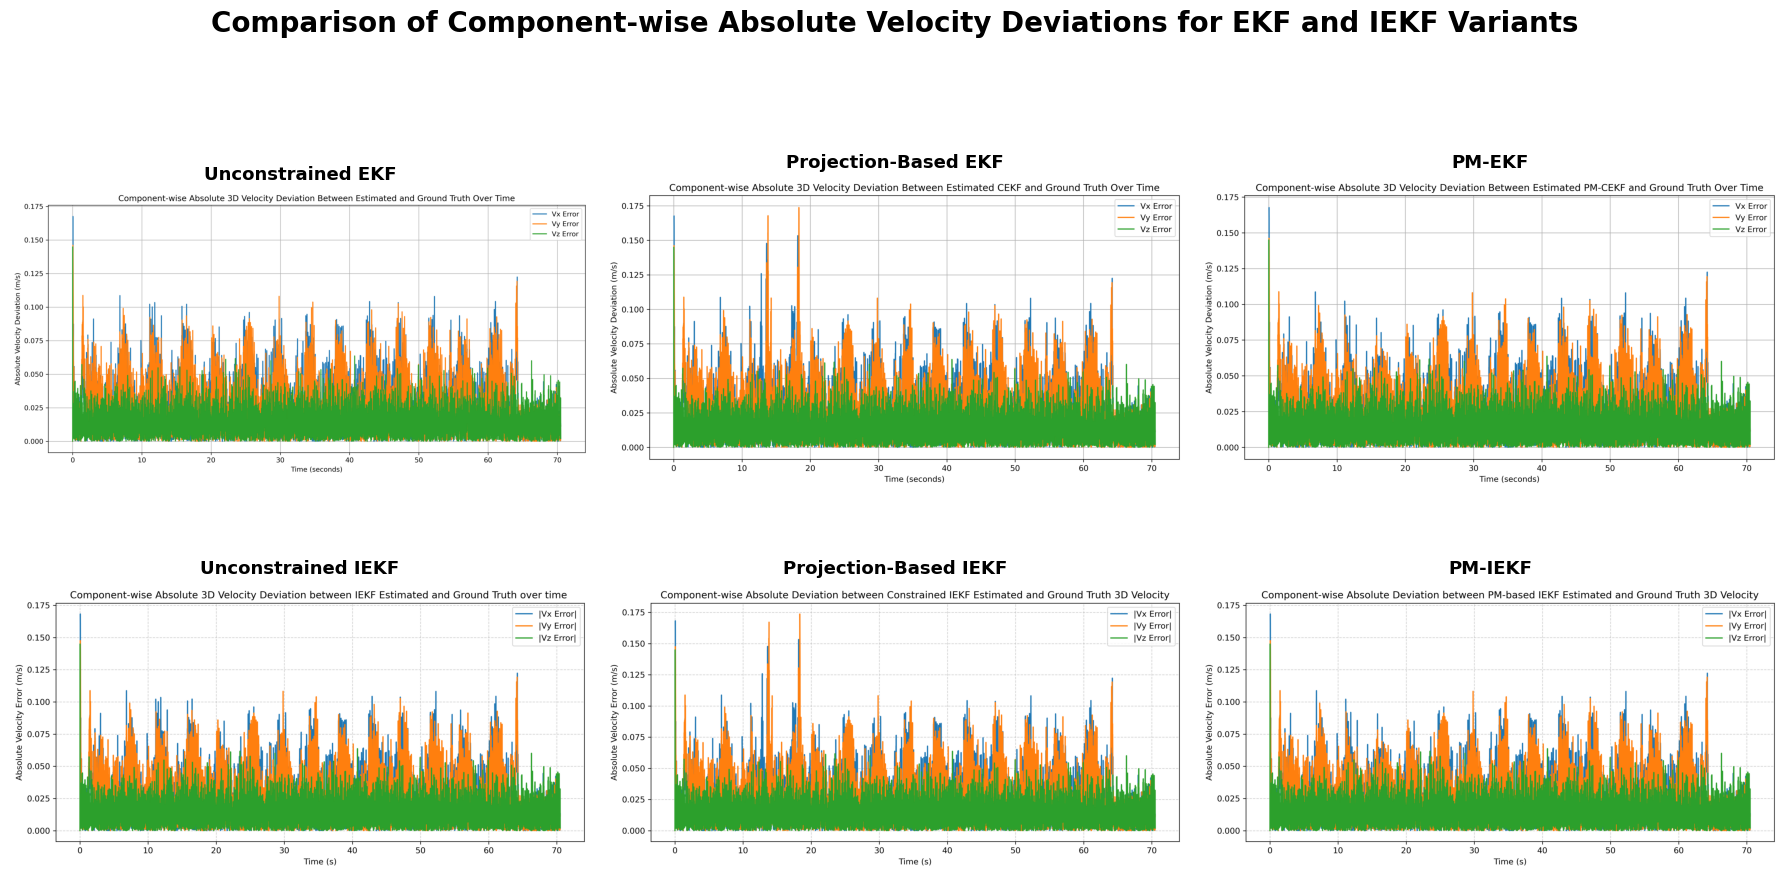

In [10]:
# Subplot titles
titles = [
    "Unconstrained EKF",
    "Projection-Based EKF",
    "PM-EKF",
    "Unconstrained IEKF",
    "Projection-Based IEKF",
    "PM-IEKF"]

# Image names
images = [
    "EKF_Velocity_Absolute_Deviation.png",
    "Projection_EKF_Velocity_Absolute_Deviation.png",
    "PM_EKF_Velocity_Absolute_Deviation.png",
    "IEKF_Velocity_Absolute_Deviation.png",
    "Projection_IEKF_Velocity_Absolute_Deviation.png",
    "PM_IEKF_Velocity_Absolute_Deviation.png"]

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, title, image in zip(axes.ravel(), titles, images):

    filepath = os.path.join(folder, image)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            f"Image Not Found\n{image}",
            ha="center",
            va="center",
            fontsize=11)

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=8)

    ax.axis("off")

plt.suptitle(
    "Comparison of Component-wise Absolute Velocity Deviations for EKF and IEKF Variants",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- All six methods produce stable velocity estimates throughout the robot tracking experiment, with the absolute velocity deviations remaining bounded over the entire trajectory.

- The unconstrained Extended Kalman Filter and Iterated Extended Kalman Filter exhibit small and consistent velocity deviations. The Iterated Extended Kalman Filter provides slightly lower deviations because the iterative measurement update reduces the effect of nonlinear linearisation errors.

- The projection-based Extended Kalman Filter and Iterated Extended Kalman Filter successfully enforce the geometric constraint while maintaining stable velocity estimation. However, the projection step introduces a slight increase in the velocity deviations compared with the corresponding unconstrained methods.

- The Perfect Measurement Extended Kalman Filter and Perfect Measurement Iterated Extended Kalman Filter achieve the smallest absolute velocity deviations among the constrained approaches by incorporating the geometric constraint directly into the measurement update. This enables the filters to improve velocity estimation while simultaneously maintaining geometric consistency.

- Comparing the constrained methods, the Perfect Measurement approach consistently outperforms the projection-based approach by producing lower velocity deviations throughout the robot trajectory.

- Overall, the Iterated Extended Kalman Filter variants provide slightly more consistent velocity estimates than the corresponding Extended Kalman Filter variants, and the Perfect Measurement Iterated Extended Kalman Filter achieves the best overall velocity estimation performance among the six methods investigated.

## 4. Comparison of Component-wise Cumulative Position RMSE for EKF and IEKF Variants

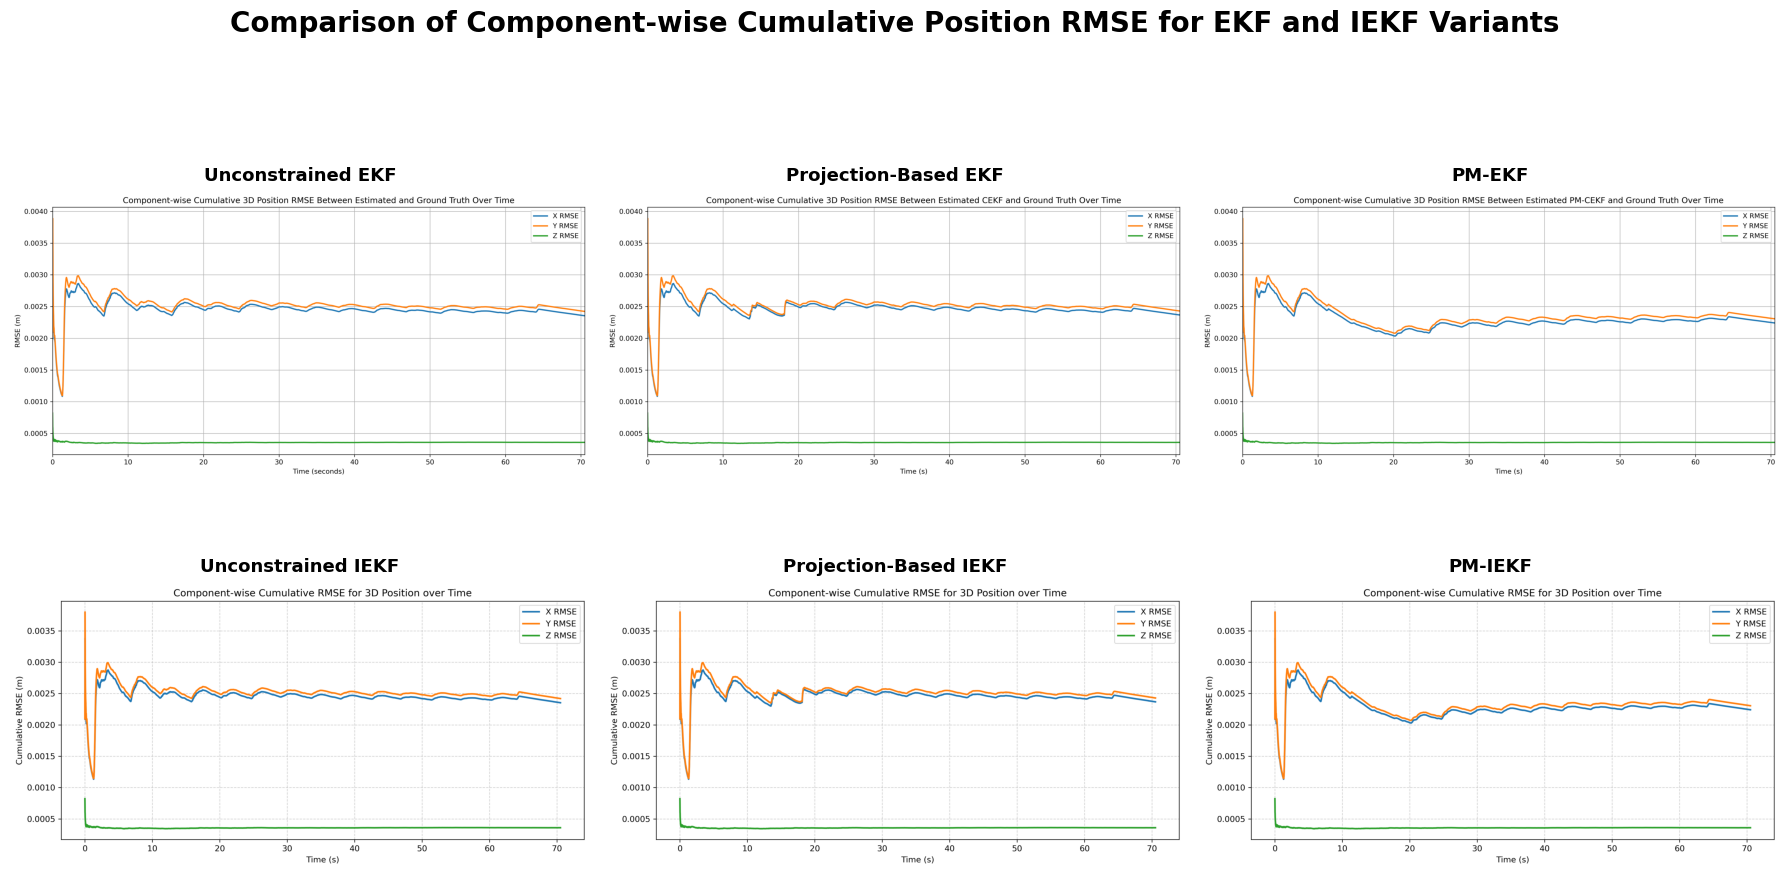

In [11]:
# Subplot titles
titles = [
    "Unconstrained EKF",
    "Projection-Based EKF",
    "PM-EKF",
    "Unconstrained IEKF",
    "Projection-Based IEKF",
    "PM-IEKF"]

# Image names
images = [
    "EKF_Component_Cumulative_PositionRMSE.png",
    "Projection_EKF_Component_Cumulative_PositionRMSE.png",
    "PM_EKF_Component_Cumulative_PositionRMSE.png",
    "IEKF_Component_Cumulative_PositionRMSE.png",
    "Projection_IEKF_Component_Cumulative_PositionRMSE.png",
    "PM_IEKF_Component_Cumulative_PositionRMSE.png"]

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, title, image in zip(axes.ravel(), titles, images):

    filepath = os.path.join(folder, image)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            f"Image Not Found\n{image}",
            ha="center",
            va="center",
            fontsize=11)

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=8)

    ax.axis("off")

plt.suptitle(
    "Comparison of Component-wise Cumulative Position RMSE for EKF and IEKF Variants",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- All six methods converge to stable cumulative position RMSE values after the initial estimation period, demonstrating stable and consistent recursive position estimation throughout the robot tracking experiment.

- The unconstrained Extended Kalman Filter and Iterated Extended Kalman Filter exhibit smooth convergence and maintain nearly constant cumulative position RMSE throughout the trajectory. The Iterated Extended Kalman Filter converges to a slightly lower steady-state RMSE because the iterative measurement update reduces the linearisation error.

- The Perfect Measurement Extended Kalman Filter and Perfect Measurement Iterated Extended Kalman Filter also converge rapidly and produce cumulative position RMSE values comparable to, or lower than, their corresponding unconstrained methods. The direct incorporation of the geometric constraint preserves stable convergence while improving estimation accuracy.

- The projection-based Extended Kalman Filter and projection-based Iterated Extended Kalman Filter exhibit a temporary increase in cumulative position RMSE during the projection stage. This behaviour is caused by the application of the geometric constraint, after which the cumulative RMSE gradually decreases and converges to a stable steady-state value.

- Comparing the Extended Kalman Filter and Iterated Extended Kalman Filter families, the Iterated Extended Kalman Filter variants consistently converge to slightly lower cumulative position RMSE values than the corresponding Extended Kalman Filter variants. Among the constrained approaches, the Perfect Measurement Iterated Extended Kalman Filter achieves the best overall cumulative position estimation performance.

## 5. Comparison of Component-wise Cumulative Velocity RMSE for EKF and IEKF Variants

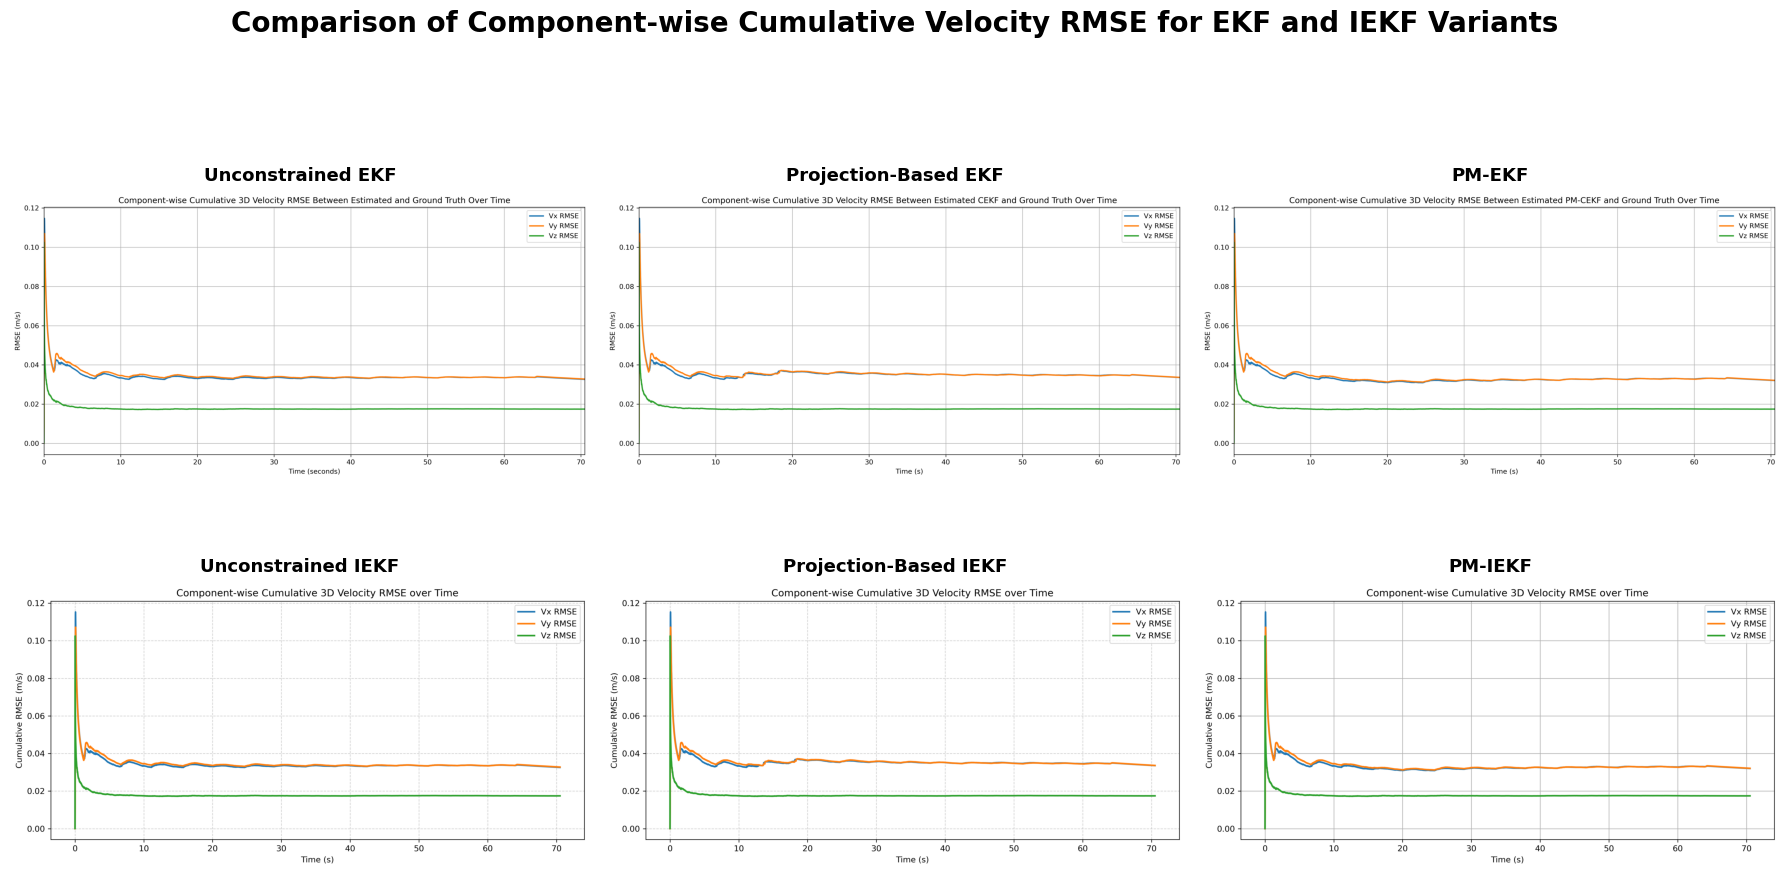

In [12]:
# Subplot titles
titles = [
    "Unconstrained EKF",
    "Projection-Based EKF",
    "PM-EKF",
    "Unconstrained IEKF",
    "Projection-Based IEKF",
    "PM-IEKF"]

# Image names
images = [
    "EKF_Component_Cumulative_VelocityRMSE.png",
    "Projection_EKF_Component_Cumulative_VelocityRMSE.png",
    "PM_EKF_Component_Cumulative_VelocityRMSE.png",
    "IEKF_Component_Cumulative_VelocityRMSE.png",
    "Projection_IEKF_Component_Cumulative_VelocityRMSE.png",
    "PM_IEKF_Component_Cumulative_VelocityRMSE.png"]

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, title, image in zip(axes.ravel(), titles, images):

    filepath = os.path.join(folder, image)

    if os.path.exists(filepath):
        img = mpimg.imread(filepath)
        ax.imshow(img)
    else:
        ax.text(
            0.5,
            0.5,
            f"Image Not Found\n{image}",
            ha="center",
            va="center",
            fontsize=11)

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=8)

    ax.axis("off")

plt.suptitle(
    "Comparison of Component-wise Cumulative Velocity RMSE for EKF and IEKF Variants",
    fontsize=20,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

### Summary:

- All six methods exhibit stable convergence of the cumulative velocity RMSE after the initial transient period, demonstrating reliable and consistent velocity estimation throughout the robot tracking experiment.

- The unconstrained Extended Kalman Filter and Iterated Extended Kalman Filter converge smoothly and maintain nearly constant cumulative velocity RMSE after reaching steady-state. The Iterated Extended Kalman Filter converges to a slightly lower steady-state RMSE because the iterative measurement update reduces the linearisation error.

- The Perfect Measurement Extended Kalman Filter and Perfect Measurement Iterated Extended Kalman Filter also converge rapidly and produce cumulative velocity RMSE values comparable to, or lower than, their corresponding unconstrained methods. Incorporating the geometric constraint directly into the measurement update preserves stable convergence while improving velocity estimation accuracy.

- The projection-based Extended Kalman Filter and projection-based Iterated Extended Kalman Filter exhibit a temporary increase in cumulative velocity RMSE during the projection stage. This behaviour results from the application of the geometric constraint, after which the cumulative RMSE gradually decreases and converges to a stable steady-state value.

- Comparing the Extended Kalman Filter and Iterated Extended Kalman Filter families, the Iterated Extended Kalman Filter variants consistently converge to slightly lower cumulative velocity RMSE values than the corresponding Extended Kalman Filter variants. Among the constrained approaches, the Perfect Measurement Iterated Extended Kalman Filter achieves the best overall cumulative velocity estimation performance.

- Overall, all six methods remain numerically stable and converge successfully. The unconstrained and Perfect Measurement approaches exhibit the smoothest convergence characteristics, whereas the projection-based approaches require a short adaptation period before reaching stable cumulative velocity RMSE values.

## 6. Overall RMSE Comparison of EKF and IEKF Variants

| **Filter** | **X RMSE (m)** | **Y RMSE (m)** | **Z RMSE (m)** | **Overall Position RMSE (m)** | **Vx RMSE (m/s)** | **Vy RMSE (m/s)** | **Vz RMSE (m/s)** | **Overall Velocity RMSE (m/s)** | **Remarks** |
|:-----------|---------------:|---------------:|---------------:|------------------------------:|------------------:|------------------:|------------------:|--------------------------------:|:------------|
| **Unconstrained EKF** | 0.002355 | 0.002423 | 0.000360 | 0.003398 | 0.032615 | 0.032794 | 0.017479 | 0.049444 | Accurate nonlinear estimation without motion constraints. |
| **Projection-Based EKF** | 0.002367 | 0.002430 | **0.000359** | 0.003411 | 0.033578 | 0.033643 | 0.017479 | 0.050645 | Enforces geometric constraints through state projection while maintaining comparable estimation accuracy. |
| **Perfect Measurement EKF** | **0.002241** | 0.002307 | **0.000359** | **0.003236** | **0.032037** | 0.032130 | **0.017478** | 0.048623 | Incorporates the geometric constraint directly into the Kalman update, providing high estimation accuracy and geometric consistency. |
| **Unconstrained IEKF** | 0.002353 | 0.002420 | **0.000359** | 0.003395 | 0.032615 | 0.032791 | 0.017479 | 0.049441 | Accurate nonlinear estimation without geometric constraints with improved iterative refinement. |
| **Projection-Based IEKF** | 0.002368 | 0.002429 | **0.000359** | 0.003411 | 0.033576 | 0.033637 | 0.017479 | 0.050639 | Maintains geometric consistency through projection with a slight increase in estimation error. |
| **Perfect Measurement IEKF** | 0.002242 | **0.002306** | **0.000359** | **0.003236** | **0.032037** | **0.032127** | **0.017478** | **0.048621** | Best overall estimation performance by combining iterative refinement with direct incorporation of the geometric constraint. |

## Improvement over Raw Sensor Measurements

| **Filter** | **Configuration** | **Position Improvement (%)** | **Velocity Improvement (%)** | **Observation** |
|:-----------|:------------------|-----------------------------:|-----------------------------:|:----------------|
| **Extended Kalman Filter** | Unconstrained | **-26.77** | **73.26** | Significantly improves velocity estimation, although the overall position error is slightly higher than the raw sensor measurements. |
| **Projection-Based Extended Kalman Filter** | Circular Projection Constraint | **-27.27** | **73.25** | The projection constraint maintains geometric consistency but introduces a slight reduction in estimation accuracy compared with the unconstrained filter. |
| **Perfect Measurement Extended Kalman Filter** | Perfect Measurement Constraint | **-20.72** | **74.32** | Provides the highest improvement within the Extended Kalman Filter family by incorporating the geometric constraint directly into the measurement update. |
| **Iterated Extended Kalman Filter** | Unconstrained | **-26.66** | **73.89** | Slightly better improvement than the Extended Kalman Filter owing to iterative measurement refinement. |
| **Projection-Based Iterated Extended Kalman Filter** | Circular Projection Constraint | **-27.26** | **73.26** | Satisfies the geometric constraint while producing a small reduction in estimation improvement because of the projection stage. |
| **Perfect Measurement Iterated Extended Kalman Filter** | Perfect Measurement Constraint | **-20.72** | **74.33** | Achieves the highest overall improvement among the six methods by combining iterative refinement with direct incorporation of the geometric constraint. |

## Computational Time Comparison of EKF and IEKF Variants

| **Filter** | **Configuration** | **Total Time (s)** | **Average Time / Epoch (ms)** | **Observation** |
|:-----------|:------------------|-------------------:|------------------------------:|:----------------|
| **Extended Kalman Filter** | Unconstrained | **1.276510** | **0.1809** | Provides accurate nonlinear state estimation with low computational cost by requiring only a single prediction and measurement update at each epoch. |
| **Projection-Based Extended Kalman Filter** | Circular Projection Constraint | **0.676464** | **0.0959** | Computationally efficient because the projection operation is applied after the standard Kalman update while maintaining geometric consistency. |
| **Perfect Measurement Extended Kalman Filter** | Perfect Measurement Constraint | **0.675531** | **0.0957** | Fastest method in the Extended Kalman Filter family, combining high estimation accuracy with the lowest computational cost by incorporating the constraint directly into the measurement model. |
| **Iterated Extended Kalman Filter** | Unconstrained | **1.933523** | **0.2740** | Highest computational cost in the Iterated Extended Kalman Filter family because multiple measurement updates are performed during each estimation epoch. |
| **Projection-Based Iterated Extended Kalman Filter** | Circular Projection Constraint | **1.612426** | **0.2285** | Requires less computation than the unconstrained Iterated Extended Kalman Filter while enforcing the geometric constraint through state projection. |
| **Perfect Measurement Iterated Extended Kalman Filter** | Perfect Measurement Constraint | **1.834185** | **0.2599** | Slightly lower computational cost than the unconstrained Iterated Extended Kalman Filter while providing the highest overall estimation accuracy among the six methods. |

**Note:** The reported computation times were obtained using the hardware and software configuration employed in this study. The absolute execution times may vary with processor specifications, memory, programming environment, and implementation details. Therefore, these values should be interpreted as a relative comparison of the computational complexity of the different filter implementations rather than absolute execution times.

## Convergence Behaviour Comparison Summary

- All six filter variants successfully converged throughout the robot tracking experiment, demonstrating that the adopted dynamic and measurement models are appropriate for constrained state estimation.

- The Unconstrained Extended Kalman Filter exhibited rapid convergence and maintained stable state estimates throughout the trajectory despite not incorporating any geometric constraints.

- The Projection-Based Extended Kalman Filter converged successfully after a short adaptation period introduced by the projection operation. Once the geometric constraint was enforced, the filter maintained stable estimation throughout the remainder of the trajectory.

- The Perfect Measurement Extended Kalman Filter demonstrated smooth and stable convergence by incorporating the geometric constraint directly into the measurement update, thereby avoiding the transient behaviour observed in the projection-based approach while improving estimation accuracy.

- The Unconstrained Iterated Extended Kalman Filter exhibited slightly better convergence than the corresponding Extended Kalman Filter because the iterative measurement update reduced the nonlinear linearisation error at each estimation epoch.

- The Projection-Based Iterated Extended Kalman Filter combined iterative refinement with geometric projection, resulting in stable convergence after a brief transient period associated with the projection stage.

- The Perfect Measurement Iterated Extended Kalman Filter demonstrated the best overall convergence behaviour among the six methods. By combining iterative measurement refinement with direct incorporation of the geometric constraint, it achieved the lowest steady-state position and velocity RMSE while maintaining stable and consistent estimation throughout the tracking experiment.

## Effect of Geometric Constraints on EKF and IEKF Estimation

- Incorporating geometric constraints improves the consistency of the estimated robot trajectory by ensuring that the state estimates satisfy the known motion path throughout the recursive estimation process.

- The Perfect Measurement Extended Kalman Filter and Perfect Measurement Iterated Extended Kalman Filter achieve the highest estimation accuracy because the geometric constraint is incorporated directly into the measurement update. Consequently, these methods produce the lowest position and velocity RMSE among both the constrained and unconstrained EKF-based approaches.

- The Projection-Based Extended Kalman Filter and Projection-Based Iterated Extended Kalman Filter also successfully enforce the geometric constraint. However, the additional projection step introduces a slight increase in position and velocity RMSE because the predicted state is projected onto an approximated circular trajectory after each update.

- The effectiveness of the projection-based approach depends strongly on the accuracy of the fitted geometric model. When the derived circular arc closely represents the true robot trajectory, the projection maintains physically consistent state estimates and stable long-term tracking performance.

- Conversely, if the fitted circular arc is inaccurate because of measurement noise, imperfect circle fitting, or incorrect selection of the constrained trajectory segment, the projection operation may introduce systematic estimation bias by forcing the state estimates towards an incorrect trajectory. This results in an increase in both the component-wise and overall estimation errors.

- Overall, the results demonstrate that geometric constraints can improve estimation performance when reliable prior knowledge of the robot trajectory is available. Among the constrained approaches, the Perfect Measurement formulations provide the best balance between estimation accuracy, numerical stability, and geometric consistency, whereas the Projection-Based methods primarily improve trajectory consistency at the expense of a small increase in estimation error.

## Final Assessment of EKF and IEKF Variants

### Unconstrained Extended Kalman Filter
Provides accurate nonlinear state estimation without incorporating geometric constraints, resulting in stable convergence and reliable position and velocity estimation throughout the robot tracking experiment.

### Projection-Based Extended Kalman Filter
Successfully enforces the geometric trajectory constraint through state projection, improving trajectory consistency while introducing a slight increase in position and velocity RMSE due to the projection operation.

### Perfect Measurement Extended Kalman Filter
Achieves the best estimation performance within the Extended Kalman Filter family by incorporating the geometric constraint directly into the measurement update, resulting in improved estimation accuracy, stable convergence, and the lowest RMSE among the EKF variants.

### Unconstrained Iterated Extended Kalman Filter
Improves upon the Extended Kalman Filter through iterative measurement refinement, reducing the nonlinear linearisation error and providing slightly lower position and velocity estimation errors while maintaining stable convergence.

### Projection-Based Iterated Extended Kalman Filter
Maintains geometric consistency by combining iterative refinement with state projection. Although the projection stage introduces a small increase in RMSE, the filter remains numerically stable and produces reliable state estimates throughout the robot tracking experiment.

### Perfect Measurement Iterated Extended Kalman Filter (Best Overall EKF/IEKF Variant)
Achieves the best overall estimation performance among all six methods by combining iterative measurement refinement with direct incorporation of the geometric constraint. This approach produces the lowest overall position and velocity RMSE while maintaining excellent numerical stability, rapid convergence, and geometric consistency throughout the robot tracking experiment.

# Final comparison among all filter models using overall rmse 

## Final Overall RMSE Comparison

| **Filter** | **Configuration** | **Position RMSE (m)** | **Velocity RMSE (m/s)** | **Remarks** |
|:-----------|:------------------|----------------------:|------------------------:|:------------|
| Linear Kalman Filter | $\sigma_a=2.5$ | 0.003397641 | 0.049443000 | Excellent estimation accuracy for the approximately linear robot tracking problem. |
| Extended Kalman Filter | Unconstrained ($\sigma_a=2.5$) | 0.003411219 | 0.050639352 | Accurate nonlinear estimation without geometric constraints. |
| Projection-Based Extended Kalman Filter | Circular Projection Constraint | 0.003411000 | 0.050645000 | Enforces geometric consistency through state projection with a slight increase in RMSE. |
| Perfect Measurement Extended Kalman Filter | Perfect Measurement Constraint | 0.003236000 | 0.048623000 | Best estimation accuracy within the Extended Kalman Filter family by incorporating the geometric constraint directly into the measurement update. |
| **Iterated Extended Kalman Filter** | **Unconstrained ($\sigma_a=2.5$)** | **0.003394869** | **0.049441306** | **Best unconstrained filter owing to iterative measurement refinement.** |
| Projection-Based Iterated Extended Kalman Filter | Circular Projection Constraint | 0.003411000 | 0.050639000 | Maintains geometric consistency with a slight increase in estimation error after projection. |
| **Perfect Measurement Iterated Extended Kalman Filter** | **Perfect Measurement Constraint** | **0.003236000** | **0.048621000** | **Best constrained filter by combining iterative refinement with direct incorporation of the geometric constraint.** |
| Unscented Kalman Filter | $\sigma_a=2.5$ | 0.003397641 | 0.049443000 | Estimation accuracy comparable to the Linear Kalman Filter while avoiding Jacobian computation. |
| Ensemble Kalman Filter | $\sigma_a=2.5,\;N_e=500$ | 0.005757305 | 0.058650516 | Stable estimation with minor stochastic sampling effects, although less accurate than the deterministic Kalman filters. |
| Particle Filter | $\sigma_a=2.5,\;N_p=1500$ | 0.008856500 | 0.069301336 | Highest estimation error among the filters because of stochastic particle propagation and resampling. |

## Improvement over Raw Sensor Measurements

| **Filter** | **Configuration** | **Position Improvement (%)** | **Velocity Improvement (%)** | **Observation** |
|:-----------|:------------------|-----------------------------:|-----------------------------:|:----------------|
| Linear Kalman Filter | $\sigma_a=2.5$ | -26.76 | 73.89 | Significant improvement in velocity estimation, although the position accuracy remains lower than the raw sensor measurements. |
| Extended Kalman Filter | Unconstrained ($\sigma_a=2.5$) | -27.27 | 73.26 | Provides substantial improvement in velocity estimation while maintaining stable nonlinear state estimation. |
| Projection-Based Extended Kalman Filter | Circular Projection Constraint | -27.27 | 73.25 | Maintains geometric consistency but introduces a slight reduction in estimation improvement because of the projection operation. |
| Perfect Measurement Extended Kalman Filter | Perfect Measurement Constraint | -20.72 | 74.32 | Best improvement within the Extended Kalman Filter family by incorporating the geometric constraint directly into the measurement update. |
| **Iterated Extended Kalman Filter** | **Unconstrained ($\sigma_a=2.5$)** | **-26.66** | **73.89** | **Best unconstrained filter owing to iterative measurement refinement.** |
| Projection-Based Iterated Extended Kalman Filter | Circular Projection Constraint | -27.26 | 73.26 | Similar behaviour to the projection-based Extended Kalman Filter while maintaining geometric consistency. |
| **Perfect Measurement Iterated Extended Kalman Filter** | **Perfect Measurement Constraint** | **-20.72** | **74.33** | **Best constrained filter, providing the highest overall improvement by combining iterative refinement with direct incorporation of the geometric constraint.** |
| Unscented Kalman Filter | $\sigma_a=2.5$ | -26.76 | 73.89 | Performance comparable to the Linear Kalman Filter while avoiding Jacobian computation. |
| Ensemble Kalman Filter | $\sigma_a=2.5,\;N_e=500$ | -114.79 | 69.03 | Improves velocity estimation but produces larger position errors because of stochastic ensemble sampling. |
| Particle Filter | $\sigma_a=2.5,\;N_p=1500$ | -230.41 | 63.40 | Improves velocity estimation but exhibits the largest position errors because of stochastic particle propagation and resampling. |

## Overall Influence of the Selected Process Noise Standard Deviation$ ,\sigma_a=2.5~\mathrm{m/s^2}$

- A common process noise standard deviation of $\sigma_a=2.5~\mathrm{m/s^2}$ was adopted for all filtering algorithms to provide a fair and consistent comparison under identical operating conditions.

- The selected value provided an effective balance between model confidence and measurement correction, enabling all filters to compensate for modelling errors arising from the constant-velocity assumption, particularly during curved sections of the robot trajectory where centripetal and tangential accelerations are not explicitly represented in the system model.

- For all filters, the horizontal position and velocity components exhibited larger RMSE values than the corresponding vertical components because the robot motion occurred predominantly in the horizontal plane, where continuous changes in direction generated greater dynamic uncertainty.

- The selected process noise prevented filter overconfidence while avoiding excessive state uncertainty, resulting in stable convergence, reliable recursive estimation, and numerically stable performance for all filtering algorithms throughout the robot tracking experiment.

- For the constrained filters, the selected process noise complemented the geometric constraints by allowing sufficient flexibility to compensate for residual modelling errors while ensuring that the estimated states remained consistent with the prescribed circular trajectory. This combination improved both estimation consistency and overall tracking accuracy.

- Although all filters employed the same process noise standard deviation, the final estimation accuracy depended primarily on the filtering strategy. The **Iterated Extended Kalman Filter** achieved the best performance among the unconstrained methods through iterative measurement refinement, whereas the **Perfect Measurement Iterated Extended Kalman Filter** achieved the highest overall estimation accuracy by combining iterative refinement with direct incorporation of the geometric constraint.

## Overall Conclusion

- All filtering approaches successfully tracked the robot trajectory and converged throughout the study, confirming that the adopted dynamic and measurement models are suitable for three-dimensional robot state estimation.

- The numerical RMSE comparison shows that the **Perfect Measurement Iterated Extended Kalman Filter** achieved the lowest overall position and velocity RMSE among all the constrained methods. Among the unconstrained approaches, the **Iterated Extended Kalman Filter** produced the lowest estimation errors, demonstrating the benefit of iterative measurement refinement for nonlinear state estimation.

- The improvement-over-measurement analysis shows that the Linear Kalman Filter, Extended Kalman Filter, Iterated Extended Kalman Filter, and Unscented Kalman Filter substantially improved the velocity estimation compared with the raw sensor measurements. Among the constrained methods, the **Perfect Measurement Iterated Extended Kalman Filter** achieved the highest overall improvement, whereas the **Iterated Extended Kalman Filter** provided the greatest improvement among the unconstrained approaches.

- The convergence analysis demonstrates that all filters converged successfully without numerical divergence. The Extended Kalman Filter and Iterated Extended Kalman Filter families exhibited rapid and stable convergence, while the projection-based methods experienced a short transient period because of the projection operation. The Perfect Measurement approaches achieved the smoothest convergence by incorporating the geometric constraint directly into the measurement update.

- Incorporating geometric constraints improved the consistency of the estimated robot trajectory. The projection-based methods successfully enforced the known motion constraint with only a small increase in estimation error, whereas the Perfect Measurement formulations provided the highest estimation accuracy while simultaneously maintaining geometric consistency.

- The Ensemble Kalman Filter provided stable estimation with satisfactory tracking performance but exhibited higher estimation errors because of stochastic ensemble sampling. The Particle Filter also maintained stable robot tracking; however, stochastic particle propagation and repeated resampling resulted in the largest position and velocity RMSE among the filters investigated.

- The choice of filter depends on the application requirements. For constrained nonlinear robot tracking problems where reliable prior geometric information is available, the **Perfect Measurement Iterated Extended Kalman Filter** is the preferred choice because it provides the highest estimation accuracy while maintaining geometric consistency. For unconstrained nonlinear state estimation, the **Iterated Extended Kalman Filter** offers the best overall compromise between estimation accuracy, convergence, and computational efficiency. The Ensemble Kalman Filter and Particle Filter remain suitable for highly nonlinear or non-Gaussian estimation problems in which conventional Kalman filter-based approaches may become less effective.

- The computational cost varied considerably among the filtering methods. Among the unconstrained approaches, the Extended Kalman Filter required the lowest computation time, whereas the Particle Filter exhibited the highest computational cost because of particle propagation, weighting, and resampling. Within the constrained methods, the Perfect Measurement Extended Kalman Filter achieved the lowest computation time while maintaining excellent estimation accuracy.

- Overall, this study demonstrates that the selection of an appropriate nonlinear filtering technique and the incorporation of reliable geometric constraints can significantly improve recursive state estimation performance. Among all the methods investigated, the **Perfect Measurement Iterated Extended Kalman Filter** emerged as the best constrained approach, while the **Iterated Extended Kalman Filter** proved to be the most effective unconstrained solution for the robot tracking problem considered in this study.